# Final 1 – Cleaning van de Citi Bike-data: van 44 zip-bestanden naar één modeltabel

| | |
|---|---|
| **Auteur(s)** | Kobe Vandenberk |
| **Wat** | Alle stappen om de ruwe ritdata van Citi Bike (juni 2013 – september 2026) om te zetten naar de tabel waarop het model traint: vertrekken per zone per uur, met het weer en het aanbod erbij. Bij elke stap: wat we vaststelden, wat we kozen en **waarom**. Alle code staat in dit notebook zelf; er is geen ander bestand nodig. |
| **Input** | alle NYC-bestanden van `https://s3.amazonaws.com/tripdata/` en de Open-Meteo archive API (beide automatisch opgehaald) |
| **Output** | in de map `citi_bike/Kobe/data`: `model_table.parquet` (alle jaren), `zones.json`, `station_zones.parquet`, en in `data/2024/` de tabellen voor de modelselectie op 2024 |
| **Volgende stap** | `02_analyse_en_modellen.ipynb` |
| **GenAI** | Code en tekst opgesteld met hulp van Claude; keuzes en resultaten nagekeken door Kobe. |

## Wat willen we voorspellen?
**Hoeveel Citi Bikes vertrekken er in een bepaalde zone van New York in een bepaald uur?** Dat moet Citi Bike weten om fietsen op tijd te herverdelen: een leeg station in de spits is een gemiste groene rit (thema *Going green*).

Daarvoor hebben we per **zone** en per **uur** het aantal **vertrekken** nodig, samen met wat op dat moment bekend is: kalender, weer en hoe groot het netwerk in die zone is. De ruwe data bevat individuele ritten (329 miljoen). Dit notebook brengt ze naar die vorm.

## Overzicht van de keuzes
| § | Probleem in de data | Keuze |
|---|---|---|
| 1 | 44 NYC-bestanden + 133 Jersey City-bestanden | alle NYC-bestanden, Jersey City niet |
| 2 | drie generaties kolomnamen en drie datumnotaties, wisselend per bestand | omzetten naar het schema van vandaag; notatie per stuk bepalen |
| 3 | jaarbestanden bevatten sommige maanden twee keer | per maand één versie |
| 4 | 329 miljoen ritten passen niet in het geheugen | in stukken lezen en meteen samenvatten |
| 5 | ritten zonder start, zonder einde, met rare duur, "dubbele" rijen | vertrek = starttijd + startstation + locatie in NYC; geen filter op ritduur |
| 6 | station-id's als getal opgeslagen; twee stelsels van id's | id's herstellen; stations via hun **locatie** behandelen |
| 7 | interne locaties, Jersey City/Hoboken | weglaten |
| 8 | fietstype en klanttype zijn tekst | categorieën; geen kenmerk voor het model |
| 9 | weer ontbreekt in de ritdata | uurlijks weer (Open-Meteo), inclusief sneeuwhoogte |
| 10 | dagen waarop het systeem dicht was; ontbrekende maanden? | gesloten dagen weglaten; controle dat er geen gaten zijn |
| 11 | 2.400 stations, te veel ruis per station | 30 zones (KMeans) op het netwerk van vandaag |
| 12 | het netwerk groeide van 330 naar 2.400 stations | aantal actieve stations per zone als kenmerk; uren zonder aanbod weglaten |
| 13 | uren zonder vertrek staan nergens in de data | volledig rooster zone × uur, met 0 |
| 14 | hoe meten we eerlijk? | test = laatste 12 maanden; tunen met backtesting |
| 17 | modelselectie op één jaar | dezelfde stappen voor 2024 apart |

**Hoe de code is opgebouwd.** Elke functie staat in de sectie waar ze uitgelegd wordt, vlak voor ze gebruikt wordt. Dezelfde functies staan ook in `citibike.py` (gebruikt door `train.py` en de werknotebooks), maar dit notebook heeft dat bestand niet nodig.

## 0. Imports en instellingen
De data komt in de map `citi_bike/Kobe/data` (één map hoger dan dit notebook), zodat de modeltabel op dezelfde plaats staat als voor `train.py` en de API.

In [1]:
%matplotlib inline
import hashlib
import io
import json
import os
import re
import time
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

KOBE = Path.cwd().parent                          # citi_bike/Kobe (dit notebook staat in citi_bike/Kobe/Final)
DATA_DIR = KOBE / "data"
RAW_DIR = DATA_DIR / "raw"
DATA_2024 = DATA_DIR / "2024"                     # tabellen voor de modelselectie op 2024
BUCKET_URL = "https://s3.amazonaws.com/tripdata/"
NYC_CENTER = (40.73, -73.97)                      # één punt voor heel NYC (weer)
NYC_BBOX = {"lat": (40.4, 41.1), "lng": (-74.4, -73.5)}
N_ZONES = 30
SEED = 42
# Windows: joblib zoekt anders het aantal fysieke kernen op en geeft een waarschuwing.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) - 1)))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
GREEN, ORANGE, INK, BLUE = "#2f6f4f", "#c47f00", "#17201b", "#3b6fb6"
pd.set_option("display.max_columns", 30)
print("Data-map:", DATA_DIR)

Data-map: C:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CloudAI-Challenge\citi_bike\Kobe\data


## 1. Welke bestanden?
**Vaststelling:** de officiële bucket bevat drie soorten bestanden:
- **2013–2023**: één zip per jaar, met daarin mappen of zip's per maand;
- **vanaf 2024**: één zip per maand, met CSV-delen van ± 1 miljoen rijen;
- **`JC-…`**: Jersey City, een apart Citi Bike-systeem aan de overkant van de Hudson.

De S3-API geeft de lijst per 1.000 bestanden terug; we volgen de *continuation token* tot alles binnen is.

In [2]:
def list_bucket() -> pd.DataFrame:
    """Alle bestanden in de S3-bucket (naam, grootte, laatst gewijzigd)."""
    ns = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}
    rows, token = [], None
    while True:
        params = {"list-type": "2", **({"continuation-token": token} if token else {})}
        root = ET.fromstring(requests.get(BUCKET_URL, params=params, timeout=60).content)
        for item in root.findall("s3:Contents", ns):
            rows.append({"file": item.find("s3:Key", ns).text, "bytes": int(item.find("s3:Size", ns).text),
                         "last_modified": item.find("s3:LastModified", ns).text})
        token = root.find("s3:NextContinuationToken", ns)
        if token is None:
            return pd.DataFrame(rows)
        token = token.text


def nyc_files(bucket: pd.DataFrame) -> pd.DataFrame:
    """Jaar-zip's (2013-2023) en maand-zip's (vanaf 2024) van NYC; de JC-bestanden vallen weg."""
    nyc = bucket[bucket["file"].str.fullmatch(r"\d{4}(\d{2})?-citibike-tripdata(\.csv)?\.zip")].copy()
    nyc["period"] = nyc["file"].str.extract(r"^(\d{4}(?:\d{2})?)")[0]
    return nyc.sort_values("period").reset_index(drop=True)


bucket = list_bucket()
files = nyc_files(bucket)
jc = bucket[bucket["file"].str.startswith("JC")]
print(f"NYC: {len(files)} bestanden, {files['bytes'].sum() / 1e9:.1f} GB ({files['period'].iloc[0]} t/m {files['period'].iloc[-1]})")
print(f"Jersey City: {len(jc)} bestanden, {jc['bytes'].sum() / 1e9:.2f} GB")

NYC: 44 bestanden, 32.5 GB (2013 t/m 202609)
Jersey City: 133 bestanden, 0.22 GB


**Keuze:** we gebruiken **alle** NYC-bestanden en **geen** Jersey City-bestanden.

**Waarom alle jaren?** In een eerste studie gebruikten we alleen 2024. Het beste model maakte toen de grootste fouten op zeldzame dagen (Kerstmis, Thanksgiving, zware regen): in één jaar zit van elke feestdag maar één voorbeeld. Met 13 jaar heeft het model er telkens een tiental. In `02_analyse_en_modellen` meten we of dat echt helpt.

**Waarom geen Jersey City?** Dat is een ander systeem met eigen stations en eigen klanten. De vraag in Manhattan of Brooklyn hangt er niet van af, en de API voorspelt alleen voor New York.

### Downloaden met controle
Elk bestand wordt eerst naar een `.part`-bestand geschreven en pas hernoemd als de grootte klopt: een afgebroken download wordt zo nooit voor een geldige zip aangezien. Daarna berekenen we een **SHA-256 checksum** (een vingerafdruk van het bestand) en bewaren die in `manifest.json`, zodat iedereen kan controleren dat hij exact dezelfde data gebruikt. Bestanden die al volledig aanwezig zijn, worden overgeslagen. Het manifest vermeldt ook welke CSV's er in elke zip zitten, ook in geneste zip's.

In [3]:
def _sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def _walk_zip(archive: ZipFile, prefix: str = ""):
    """(volledige naam, archief, naam in archief) voor elke CSV, ook in geneste zip's (die openen we in het geheugen)."""
    for name in sorted(archive.namelist()):
        base = Path(name).name
        if name.endswith("/") or "__MACOSX" in name or base.startswith("._"):
            continue
        if name.lower().endswith(".zip"):
            with ZipFile(io.BytesIO(archive.read(name))) as inner:
                yield from _walk_zip(inner, f"{prefix}{name}/")
        elif name.lower().endswith(".csv"):
            yield f"{prefix}{name}", archive, name


def list_csvs(zip_path: Path) -> list[str]:
    with ZipFile(zip_path) as archive:
        return [full for full, _, _ in _walk_zip(archive)]


def download_file(name: str, size: int, raw_dir: Path = RAW_DIR) -> dict:
    """Download één bestand (als het nog niet volledig aanwezig is) en geef een manifest-regel terug."""
    raw_dir.mkdir(parents=True, exist_ok=True)
    url = BUCKET_URL + name
    target = raw_dir / name
    if target.exists() and target.stat().st_size == size:
        status = "al aanwezig"
    else:
        partial = target.with_suffix(".part")
        if not (partial.exists() and partial.stat().st_size == size):
            with requests.get(url, stream=True, timeout=(15, 300)) as response:
                response.raise_for_status()
                with partial.open("wb") as handle:
                    for block in response.iter_content(chunk_size=8 * 1024 * 1024):
                        handle.write(block)
        if partial.stat().st_size != size:
            raise IOError(f"{name}: download onvolledig ({partial.stat().st_size} van {size} bytes)")
        for attempt in range(10):          # Windows: de virusscanner houdt een vers bestand soms even vast
            try:
                partial.replace(target)
                break
            except PermissionError:
                time.sleep(3)
        else:
            partial.replace(target)
        status = "gedownload"
    return {"file": name, "url": url, "bytes": size, "csv_files": list_csvs(target),
            "sha256": _sha256(target), "status": status,
            "recorded_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}


def download_all(raw_dir: Path = RAW_DIR) -> pd.DataFrame:
    """Download alle NYC-bestanden en schrijf data/raw/manifest.json (bron, grootte, checksum, CSV's)."""
    records = []
    for row in nyc_files(list_bucket()).itertuples():
        started = datetime.now()
        record = download_file(row.file, row.bytes, raw_dir)
        print(f"{row.file:<36} {record['status']:<11} {row.bytes / 1e9:5.2f} GB, "
              f"{len(record['csv_files']):>3} CSV's ({(datetime.now() - started).seconds} s)", flush=True)
        records.append(record)
        (raw_dir / "manifest.json").write_text(json.dumps(records, indent=2), encoding="utf-8")
    return pd.DataFrame(records)


manifest = download_all()
print(f"{len(manifest)} bestanden, {manifest['bytes'].sum() / 1e9:.1f} GB, {manifest['csv_files'].str.len().sum()} CSV's")
manifest["status"].value_counts()

2013-citibike-tripdata.zip           al aanwezig  0.33 GB,  17 CSV's (0 s)


2014-citibike-tripdata.zip           al aanwezig  0.22 GB,  12 CSV's (0 s)


2015-citibike-tripdata.zip           al aanwezig  0.28 GB,  16 CSV's (0 s)


2016-citibike-tripdata.zip           al aanwezig  0.44 GB,  20 CSV's (1 s)


2017-citibike-tripdata.zip           al aanwezig  0.56 GB,  20 CSV's (1 s)


...

202607-citibike-tripdata.zip         al aanwezig  0.97 GB,   5 CSV's (3 s)


202608-citibike-tripdata.zip         al aanwezig  1.02 GB,   6 CSV's (3 s)


202609-citibike-tripdata.zip         al aanwezig  0.97 GB,   5 CSV's (3 s)


44 bestanden, 32.5 GB, 426 CSV's


status
al aanwezig    44
Name: count, dtype: int64

## 2. Drie generaties kolomnamen en drie datumnotaties
**Vaststelling:** we lezen van **elke** CSV (alle 426) de kolomnamen en de eerste 200 starttijden, en bepalen welke datumnotatie die CSV gebruikt.

Eerst de functies:
- `standardize_columns` zet alle kolomnamen om naar het schema van vandaag;
- `to_datetime` probeert de drie notaties na elkaar en neemt de eerste die (bijna) alles kan lezen;
- `parse_chunk` zet tekst om naar de juiste types en berekent de ritduur.

In [4]:
RAW_COLUMNS = ["ride_id", "rideable_type", "started_at", "ended_at", "start_station_name",
               "start_station_id", "end_station_name", "end_station_id", "start_lat", "start_lng",
               "end_lat", "end_lng", "member_casual"]
COLUMN_ALIASES = {"starttime": "started_at", "start_time": "started_at", "stoptime": "ended_at",
                  "stop_time": "ended_at", "start_station_latitude": "start_lat",
                  "start_station_longitude": "start_lng", "end_station_latitude": "end_lat",
                  "end_station_longitude": "end_lng", "usertype": "member_casual", "user_type": "member_casual",
                  "bikeid": "bike_id"}
DATE_FORMATS = ["ISO8601", "%m/%d/%Y %H:%M:%S", "%m/%d/%Y %H:%M"]


def standardize_columns(chunk: pd.DataFrame) -> pd.DataFrame:
    """Hernoem naar het schema van vandaag; ontbrekende kolommen worden leeg (of 'unknown')."""
    chunk = chunk.rename(columns=lambda c: re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_"))
    chunk = chunk.rename(columns=COLUMN_ALIASES)
    if "member_casual" in chunk:
        chunk["member_casual"] = (chunk["member_casual"].str.strip().str.lower()
                                  .replace({"subscriber": "member", "customer": "casual"}))
    if "rideable_type" not in chunk:
        chunk["rideable_type"] = "unknown"          # fietstype staat pas sinds 2020 in de data
    return chunk.reindex(columns=RAW_COLUMNS)


def to_datetime(values: pd.Series) -> pd.Series:
    """Eén vaste notatie per stuk: de eerste die >= 99% van de waarden kan lezen (snel, en kapotte waarden worden NaT)."""
    best, filled = None, values.notna().sum()
    for fmt in DATE_FORMATS:
        parsed = pd.to_datetime(values, format=fmt, errors="coerce")
        if parsed.notna().sum() >= 0.99 * filled:
            return parsed
        if best is None or parsed.notna().sum() > best.notna().sum():
            best = parsed
    return best


def parse_chunk(chunk: pd.DataFrame) -> pd.DataFrame:
    """Tekst -> juiste types, plus de ritduur in minuten."""
    out = chunk.copy()
    for column in ["started_at", "ended_at"]:
        out[column] = to_datetime(out[column])
    for column in ["start_lat", "start_lng", "end_lat", "end_lng"]:
        out[column] = pd.to_numeric(out[column], errors="coerce")
    out["duration_min"] = (out["ended_at"] - out["started_at"]).dt.total_seconds() / 60
    return out


def date_format(values: pd.Series) -> str:
    for fmt in DATE_FORMATS:
        if pd.to_datetime(values, format=fmt, errors="coerce").notna().mean() >= 0.99:
            return fmt
    return "onleesbaar"


scan = []
for record in manifest.to_dict("records"):
    with ZipFile(RAW_DIR / record["file"]) as archive:
        for full, holder, name in _walk_zip(archive):
            with holder.open(name) as handle:
                head = pd.read_csv(handle, dtype=str, nrows=200)
            scan.append({"bestand": record["file"], "jaar": record["file"][:4], "csv": full,
                         "kolommen": ", ".join(head.columns[:4]) + ", ...", "n_kolommen": head.shape[1],
                         "notatie": date_format(standardize_columns(head)["started_at"])})
scan = pd.DataFrame(scan)
print(f"{len(scan)} CSV's gelezen")
display(scan.groupby(["kolommen", "n_kolommen"]).agg(csvs=("csv", "size"), jaren=("jaar", lambda s: f"{s.min()}–{s.max()}")))
pd.crosstab(scan["jaar"], scan["notatie"]).T

426 CSV's gelezen


,,csvs,jaren
kolommen,n_kolommen,,
"Trip Duration, Start Time, Stop Time, Start Station ID, ...",15,8,2016–2017
"ride_id, rideable_type, started_at, ended_at, ...",13,280,2020–2026
"tripduration, starttime, stoptime, start station id, ...",15,138,2013–2019


jaar,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
notatie,,,,,,,,,,,,,,
%m/%d/%Y %H:%M,0,0,4,0,0,0,0,0,0,0,0,0,0,0
%m/%d/%Y %H:%M:%S,0,4,12,15,0,0,0,0,0,0,0,0,0,0
ISO8601,17,8,0,5,20,35,26,27,36,36,40,50,53,38


**Kolomnamen:**
- **2013–2019**: `tripduration, starttime, stoptime, start station id, ...` (15 kolommen, met `bikeid`, `usertype`, `birth year`, `gender`);
- **enkele bestanden in 2016–2017**: dezelfde kolommen met hoofdletters en spaties (`Trip Duration, Start Time, ...`);
- **vanaf 2020**: `ride_id, rideable_type, started_at, ended_at, ...` (13 kolommen, zonder leeftijd en geslacht, met fietstype).

(De tabellen tellen CSV's: 138 met de oude namen, 8 met hoofdletters, 280 met de namen van vandaag.)

**Datumnotaties:** `2013-06-01 00:00:01` (ISO), `10/1/2014 00:00:27` en `1/1/2015 0:01`. In 2014–2016 wisselt de notatie van CSV tot CSV (bv. 2015: 4 CSV's zonder seconden, 12 met), maar elke CSV begint met één vaste notatie.

**Keuze:**
- alles omzetten naar het schema van vandaag (`standardize_columns`): namen naar kleine letters met `_`, `starttime`/`start_time` → `started_at`, `usertype` → `member_casual` (*Subscriber* → member, *Customer* → casual). Wat vroeger niet bestond, wordt leeg (`ride_id`) of `unknown` (`rideable_type`);
- de datumnotatie **per stuk** bepalen (`to_datetime`). Een stuk komt altijd uit één CSV, dus uit één notatie.

**Waarom zo?** Het model voorspelt vanaf nu, dus het schema van vandaag is de referentie. Leeftijd en geslacht gooien we niet bewust weg: ze bestaan niet meer na 2020 (en bij een voorspelling van de vraag weet je niet wie er zal fietsen). Per rij de notatie laten raden (`format="mixed"`) is tientallen keren trager op 329 miljoen rijen en kan stilzwijgend dag en maand verwisselen. Het bewijs dat het werkt: in de audit (§4) heeft **geen enkele** rit een onleesbare starttijd.

## 3. Dezelfde maand twee keer in één bestand
**Vaststelling:** in het bestand van 2013 staat elke maand twee keer: één keer als los bestand (`201309-citibike-tripdata.csv`) en één keer in een maandmap, opgesplitst (`9_September/201309-citibike-tripdata_1.csv` + `_2.csv`). Zijn dat echt dezelfde ritten?

In [5]:
def csv_month(name: str) -> str | None:
    match = re.search(r"(20\d{2})(0[1-9]|1[0-2])", Path(name).name)
    return match.group(0) if match else None


versions = {}
with ZipFile(RAW_DIR / "2013-citibike-tripdata.zip") as archive:
    for full, holder, name in _walk_zip(archive):
        if csv_month(full) == "201309":
            with holder.open(name) as handle:
                part = standardize_columns(pd.read_csv(handle, dtype=str))
            versions.setdefault("los bestand" if full.count("/") == 1 else "maandmap", []).append(part)
versions = {k: pd.concat(v, ignore_index=True) for k, v in versions.items()}
a, b = (parse_chunk(v)[["started_at", "start_station_id", "end_station_id"]] for v in versions.values())
same = pd.merge(a.value_counts().rename("n").reset_index(), b.value_counts().rename("n").reset_index(),
                on=["started_at", "start_station_id", "end_station_id", "n"])["n"].sum()
for key, frame in versions.items():
    print(f"{key:12}: {len(frame):>9,} ritten")
print(f"identiek in beide versies (starttijd + start- en eindstation): {same:,}")

los bestand : 1,034,359 ritten
maandmap    : 1,034,359 ritten
identiek in beide versies (starttijd + start- en eindstation): 1,034,359


**Keuze:** per maand houden we **één versie**, die in de diepste map (`select_csvs`): de opgesplitste delen, zoals in alle andere jaren.

**Waarom:** beide versies bevatten exact dezelfde ritten. Gebruiken we ze allebei, dan telt elke rit van die maanden dubbel en zou het model een kunstmatige piek leren. Hetzelfde probleem zit in het jaarbestand van 2018.

In [6]:
def select_csvs(names: list[str]) -> tuple[list[str], list[str]]:
    """Per maand één versie van de data: (gebruikt, weggelaten). We houden de versie in de diepste map."""
    by_month: dict[str, dict[str, list[str]]] = {}
    for name in names:
        by_month.setdefault(csv_month(name) or "onbekend", {}).setdefault(str(Path(name).parent), []).append(name)
    keep, dropped = [], []
    for groups in by_month.values():
        best = max(groups, key=lambda parent: (parent.count("/") + parent.count("\\"), len(groups[parent])))
        for parent, names_ in groups.items():
            (keep if parent == best else dropped).extend(names_)
    return sorted(keep), sorted(dropped)


dropped_versions = {r["file"]: select_csvs(r["csv_files"])[1] for r in manifest.to_dict("records")}
dropped_versions = {k: v for k, v in dropped_versions.items() if v}
print({k: len(v) for k, v in dropped_versions.items()}, "->", sum(map(len, dropped_versions.values())), "weggelaten CSV's")
print("bv.", dropped_versions["2013-citibike-tripdata.zip"][:2])

{'2013-citibike-tripdata.zip': 7, '2018-citibike-tripdata.zip': 14} -> 21 weggelaten CSV's
bv. ['2013-citibike-tripdata/201306-citibike-tripdata.csv', '2013-citibike-tripdata/201307-citibike-tripdata.csv']


## 4. In stukken lezen en meteen samenvatten
**Vaststelling:** 329 miljoen ritten met 13 kolommen tekst passen niet in het geheugen van een laptop. Voor onze vraag hebben we de individuele ritten ook niet nodig: we tellen vertrekken.

**Keuze:** `aggregate_all` leest elk bestand in stukken van 500.000 rijen en houdt per stuk enkel bij:
- het aantal vertrekken per station per uur (+ hoeveel daarvan members / e-bikes waren);
- een stationslijst (naam, som van de coördinaten om het gemiddelde te kunnen nemen, eerste en laatste gebruik);
- een **audit per maand**: rijen, ontbrekende waarden per kolom, duplicaten, wat we weglieten;
- een ruwe **steekproef van 0,2%** van alle ritten (nog als tekst), om individuele ritten te kunnen bekijken.

De resultaten worden per bronbestand weggeschreven: zo blijft het geheugengebruik beperkt en kan een onderbroken run hervatten (al verwerkte bestanden worden overgeslagen; de eerste keer duurt dit ± 45 minuten).

Wat een **vertrek** is (`departure_mask`) en hoe de **station-id's** hersteld worden (`normalize_station_id`), lichten we toe in §5 en §6; hier staat de code omdat de samenvatting ze nodig heeft.

In [7]:
LEGACY_ID_CUTOFF = pd.Timestamp("2021-02-01")   # tot dan gehele station-id's (bv. 72), daarna 7407.13


def normalize_station_id(ids: pd.Series, legacy: pd.Series | None = None) -> pd.Series:
    """Station-id's die als getal werden opgeslagen terugzetten: '3423.1' -> '3423.10' (nieuw systeem),
    '119.0' -> '119' (oud systeem, ritten vóór februari 2021). Tekst-id's (HB101, JC023) blijven ongemoeid."""
    legacy = pd.Series(False, index=ids.index) if legacy is None else legacy.fillna(False)
    one_decimal = ids.str.fullmatch(r"\d+\.\d", na=False) & ~legacy
    float_int = ids.str.fullmatch(r"\d+\.0+", na=False) & legacy
    return ids.mask(one_decimal, ids + "0").mask(float_int, ids.str.replace(r"\.0+$", "", regex=True))


def departure_mask(trips: pd.DataFrame) -> pd.Series:
    """Een vertrek = starttijd + startstation + startcoördinaten binnen NYC. De ritduur speelt bewust geen rol."""
    lat_ok = trips["start_lat"].between(*NYC_BBOX["lat"])
    lng_ok = trips["start_lng"].between(*NYC_BBOX["lng"])
    return trips["started_at"].notna() & trips["start_station_id"].notna() & lat_ok & lng_ok


def _new_audit(file: str, month: str) -> dict:
    return {"file": file, "month": month, "csv_files": [], "rows": 0, "missing": {c: 0 for c in RAW_COLUMNS},
            "no_start_time": 0, "no_start_station": 0, "outside_nyc": 0, "departures": 0,
            "duration_negative": 0, "duration_over_24h": 0, "station_id_fixed": 0, "_hashes": []}


def combine_stations(parts: pd.DataFrame) -> pd.DataFrame:
    """Stationsdelen samenvoegen (som van coördinaten en ritten, eerste/laatste gebruik, laatste naam)."""
    return (parts.sort_values("last_time").groupby("start_station_id", as_index=False)
                 .agg(name=("name", "last"), lat_sum=("lat_sum", "sum"), lng_sum=("lng_sum", "sum"),
                      trips=("trips", "sum"), first_time=("first_time", "min"), last_time=("last_time", "max")))


def aggregate_file(zip_path: Path, sample_frac: float = 0.002, seed: int = SEED):
    """Eén passage door een bronbestand: (vertrekken per station per uur, stationslijst, audits, steekproef)."""
    rng = np.random.default_rng(seed)
    keep, dropped = select_csvs(list_csvs(zip_path))
    keep = set(keep)
    station_hour, stations, samples, audits = [], [], [], {}
    with ZipFile(zip_path) as archive:
        for full, holder, name in _walk_zip(archive):
            if full not in keep:
                continue
            month = csv_month(full) or "onbekend"
            audit = audits.setdefault(month, _new_audit(zip_path.name, month))
            audit["csv_files"].append(full)
            with holder.open(name) as handle:
                for chunk in pd.read_csv(handle, dtype=str, chunksize=500_000):
                    chunk = standardize_columns(chunk)
                    audit["rows"] += len(chunk)
                    for column in RAW_COLUMNS:
                        audit["missing"][column] += int(chunk[column].isna().sum())
                    # Duplicaten: oude data heeft geen ride_id, dus we vergelijken de hele rit.
                    key = chunk[["ride_id", "started_at", "ended_at", "start_station_id", "end_station_id"]]
                    audit["_hashes"].append(pd.util.hash_pandas_object(key, index=False).to_numpy())
                    samples.append(chunk.loc[rng.random(len(chunk)) < sample_frac].assign(source_file=zip_path.name))

                    trips = parse_chunk(chunk)
                    fixed = normalize_station_id(trips["start_station_id"], trips["started_at"] < LEGACY_ID_CUTOFF)
                    audit["station_id_fixed"] += int((trips["start_station_id"].notna() & (fixed != trips["start_station_id"])).sum())
                    trips["start_station_id"] = fixed
                    audit["no_start_time"] += int(trips["started_at"].isna().sum())
                    audit["no_start_station"] += int(trips["start_station_id"].isna().sum())
                    audit["duration_negative"] += int((trips["duration_min"] < 0).sum())
                    audit["duration_over_24h"] += int((trips["duration_min"] > 24 * 60).sum())

                    ok = departure_mask(trips)
                    known = trips["start_station_id"].notna() & trips["started_at"].notna()
                    audit["outside_nyc"] += int((known & ~ok).sum())
                    trips = trips.loc[ok]
                    audit["departures"] += len(trips)
                    trips = trips.assign(time=trips["started_at"].dt.floor("h"),
                                         member=(trips["member_casual"] == "member").astype("int32"),
                                         electric=(trips["rideable_type"] == "electric_bike").astype("int32"))
                    station_hour.append(trips.groupby(["start_station_id", "time"])
                                             .agg(trips=("time", "size"), members=("member", "sum"),
                                                  electric=("electric", "sum")).reset_index())
                    stations.append(trips.groupby("start_station_id")
                                         .agg(name=("start_station_name", "last"), lat_sum=("start_lat", "sum"),
                                              lng_sum=("start_lng", "sum"), trips=("time", "size"),
                                              first_time=("time", "min"), last_time=("time", "max")).reset_index())
    for audit in audits.values():
        hashes = np.concatenate(audit.pop("_hashes"))
        audit["duplicate_rows"] = int(len(hashes) - len(np.unique(hashes)))
    result = list(audits.values())
    if dropped:
        result.append({"file": zip_path.name, "month": "dubbele versies (weggelaten)", "csv_files": dropped})
    station_hour = (pd.concat(station_hour).groupby(["start_station_id", "time"], as_index=False)
                      [["trips", "members", "electric"]].sum())
    return station_hour, combine_stations(pd.concat(stations)), result, pd.concat(samples, ignore_index=True)


def aggregate_all(raw_dir: Path = RAW_DIR, out_dir: Path = DATA_DIR, sample_frac: float = 0.002) -> dict:
    """Elk bronbestand uit het manifest samenvatten; per bestand apart bewaard (hervatbaar).

    data/station_hour/<periode>.parquet  vertrekken per station per uur (enkel uren met >= 1 vertrek)
    data/stations.parquet                station-id, naam, gemiddelde coördinaten, ritten, eerste/laatste gebruik
    data/audit.json                      per maand: rijen, ontbrekende waarden, duplicaten, wat werd weggelaten
    data/trips_sample.parquet            ruwe steekproef (0,2%) van alle ritten
    """
    files = [r["file"] for r in json.loads((raw_dir / "manifest.json").read_text(encoding="utf-8"))]
    parts = {name: out_dir / name for name in ["station_hour", "_stations", "_samples", "_audits"]}
    for directory in parts.values():
        directory.mkdir(parents=True, exist_ok=True)
    for file in files:
        period = file.split("-")[0]
        if (parts["_audits"] / f"{period}.json").exists():
            print(f"{file:<36} al verwerkt", flush=True)
            continue
        started = datetime.now()
        sh, st, audits, sample = aggregate_file(raw_dir / file, sample_frac)
        sh.to_parquet(parts["station_hour"] / f"{period}.parquet", index=False)
        st.to_parquet(parts["_stations"] / f"{period}.parquet", index=False)
        sample.to_parquet(parts["_samples"] / f"{period}.parquet", index=False)
        (parts["_audits"] / f"{period}.json").write_text(json.dumps(audits, indent=2, default=str), encoding="utf-8")
        rows, deps = sum(a.get("rows", 0) for a in audits), sum(a.get("departures", 0) for a in audits)
        print(f"{file:<36} {rows:>12,} rijen -> {deps:>12,} vertrekken ({(datetime.now() - started).seconds} s)", flush=True)

    stations = combine_stations(pd.concat(pd.read_parquet(p) for p in sorted(parts["_stations"].glob("*.parquet"))))
    stations["lat"] = stations.pop("lat_sum") / stations["trips"]
    stations["lng"] = stations.pop("lng_sum") / stations["trips"]
    stations = stations[["start_station_id", "name", "lat", "lng", "trips", "first_time", "last_time"]]
    stations.to_parquet(out_dir / "stations.parquet", index=False)
    pd.concat(pd.read_parquet(p) for p in sorted(parts["_samples"].glob("*.parquet"))).to_parquet(
        out_dir / "trips_sample.parquet", index=False)
    audits = [a for p in sorted(parts["_audits"].glob("*.json")) for a in json.loads(p.read_text(encoding="utf-8"))]
    (out_dir / "audit.json").write_text(json.dumps(audits, indent=2), encoding="utf-8")
    return {"stations": stations, "audit": audits}


result = aggregate_all()
audit = pd.json_normalize([a for a in result["audit"] if "rows" in a]).set_index("month").sort_index()
n_dropped = sum(len(a["csv_files"]) for a in result["audit"] if "rows" not in a)
per_year = (audit.assign(jaar=audit.index.str[:4]).groupby("jaar")
                 [["rows", "departures", "no_start_time", "no_start_station", "outside_nyc", "duplicate_rows",
                   "duration_negative", "duration_over_24h", "station_id_fixed"]].sum())
print(f"{audit['rows'].sum():,} ritten, {audit['departures'].sum():,} vertrekken "
      f"({audit['departures'].sum() / audit['rows'].sum():.3%}); weggelaten dubbele CSV-versies: {n_dropped}")
per_year

2013-citibike-tripdata.zip           al verwerkt


2014-citibike-tripdata.zip           al verwerkt


2015-citibike-tripdata.zip           al verwerkt


2016-citibike-tripdata.zip           al verwerkt


2017-citibike-tripdata.zip           al verwerkt


...

202607-citibike-tripdata.zip         al verwerkt


202608-citibike-tripdata.zip         al verwerkt


202609-citibike-tripdata.zip         al verwerkt


328,800,493 ritten, 328,708,160 vertrekken (99.972%); weggelaten dubbele CSV-versies: 21


,rows,departures,no_start_time,no_start_station,outside_nyc,duplicate_rows,duration_negative,duration_over_24h,station_id_fixed
jaar,,,,,,,,,
2013,5614888,5614888,0,0,0,177,0,633,0
2014,8081216,8081216,0,0,0,211,0,553,0
2015,9937969,9937969,0,0,0,42118,70,2588,0
2016,13845655,13845652,0,0,3,7349,83,3579,0
2017,16364657,16364532,0,0,125,6539,49,4169,0
2018,17548339,17545761,0,2497,81,0,0,4525,8008081
2019,20551697,20551517,0,180,0,0,0,6120,7764099
2020,19562314,19562197,0,111,6,0,0,15221,0
2021,27130122,27129629,0,493,0,0,278,25198,45842


## 5. Wat telt als een vertrek?
De target is het aantal **vertrekken**: fietsen die op een bepaald uur uit een station vertrekken. We bekijken eerst welke gegevens ontbreken (op alle 329 miljoen rijen, uit de audit).

In [8]:
missing = audit.filter(like="missing.").sum().rename(lambda c: c.replace("missing.", "")).astype(int)
pd.DataFrame({"ontbrekend": missing.map("{:,}".format), "% van alle ritten": (missing / audit["rows"].sum() * 100).round(3)})

,ontbrekend,% van alle ritten
ride_id,"91,944,421",27.964
rideable_type,0,0.000
started_at,0,0.000
ended_at,0,0.000
start_station_name,"92,077",0.028
start_station_id,"92,077",0.028
end_station_name,"666,910",0.203
end_station_id,"692,918",0.211
start_lat,"88,753",0.027
start_lng,"88,753",0.027


- `ride_id` ontbreekt in alle 91,9 miljoen ritten vóór 2020 (die kolom bestond toen niet), en `rideable_type` is dan `unknown`: geen probleem voor het tellen van vertrekken.
- `start_station_*` ontbreekt bij 92.077 ritten (0,03%), en dan ontbreken bijna altijd ook de startcoördinaten (88.753 ritten zonder `start_lat/lng`).
- `end_*` ontbreekt vaker (± 0,2%): ritten die niet aan een station eindigden.
- `member_casual` ontbreekt bij 51.780 ritten (0,02%, oude data met een leeg klanttype): voor het tellen van vertrekken maakt dat niets uit.

**Ritten zonder eindstation: wat zijn het?** In de steekproef van 0,2% (vanaf 2020, toen het fietstype in de data kwam). De steekproef komt uit verschillende CSV's met verschillende notaties, dus hier proberen we per rij de drie notaties na elkaar.

In [9]:
def parse_mixed(values: pd.Series) -> pd.Series:
    """Alleen voor de steekproef (rijen uit verschillende CSV's): per rij de eerste notatie die lukt."""
    out = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns]")
    for fmt in DATE_FORMATS:
        todo = out.isna()
        out[todo] = pd.to_datetime(values[todo], format=fmt, errors="coerce")
    return out


sample = pd.read_parquet(DATA_DIR / "trips_sample.parquet")
sample["jaar"] = sample["source_file"].str[:4].astype(int)
for column in ["started_at", "ended_at"]:
    sample[column] = parse_mixed(sample[column])
sample["duration_min"] = (sample["ended_at"] - sample["started_at"]).dt.total_seconds() / 60
recent = sample[sample["jaar"] >= 2020].assign(geen_einde=lambda d: d["end_station_id"].isna(),
                                               ebike=lambda d: d["rideable_type"] == "electric_bike")
pd.DataFrame({"% zonder eindstation": recent.groupby("jaar")["geen_einde"].mean() * 100,
              "% e-bike, zonder einde": recent[recent["geen_einde"]].groupby("jaar")["ebike"].mean() * 100,
              "% e-bike, alle ritten": recent.groupby("jaar")["ebike"].mean() * 100,
              "mediane duur (min), zonder einde": recent[recent["geen_einde"]].groupby("jaar")["duration_min"].median(),
              "mediane duur (min), alle ritten": recent.groupby("jaar")["duration_min"].median()}).round(1).T

jaar,2020,2021,2022,2023,2024,2025,2026
% zonder eindstation,0.2,0.3,0.2,0.3,0.3,0.3,0.3
"% e-bike, zonder einde",16.5,29.4,56.7,82.3,91.3,92.8,91.2
"% e-bike, alle ritten",14.0,31.9,39.1,50.2,66.0,70.5,72.4
"mediane duur (min), zonder einde",55.8,58.1,1340.4,81.8,63.1,39.0,61.1
"mediane duur (min), alle ritten",12.9,11.1,10.2,9.3,9.1,8.8,9.2


**Ritduur.** Hoe lang duren de ritten, en zijn er ritten van minder dan een minuut (valse starts)?

count    657661.0
mean         18.1
std         879.0
min         -49.5
1%            1.5
50%           9.9
99%          68.0
99.9%       521.0
max      569585.7
Korter dan 1 minuut per jaar (steekproef): {2021: 2, 2023: 1}
Langer dan 24 uur (alle data, audit): 157,541; negatief (audit): 1,962


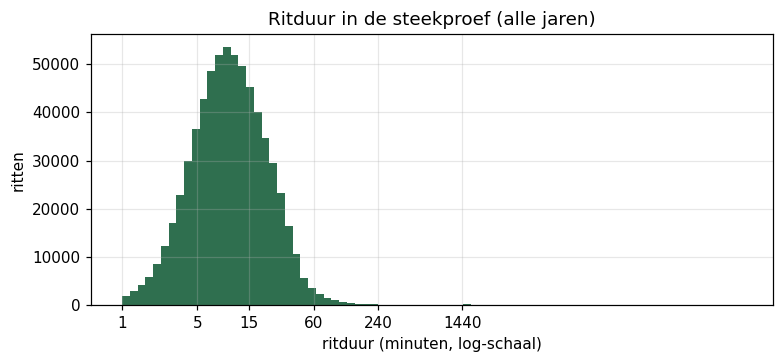

In [10]:
d = sample["duration_min"]
print(d.describe(percentiles=[.01, .5, .99, .999]).round(1).to_string())
print("Korter dan 1 minuut per jaar (steekproef):", sample.loc[d.between(0, 1, inclusive="left"), "jaar"].value_counts().sort_index().to_dict())
print(f"Langer dan 24 uur (alle data, audit): {int(audit['duration_over_24h'].sum()):,}; "
      f"negatief (audit): {int(audit['duration_negative'].sum()):,}")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(np.log10(d[d > 0].clip(lower=1).to_numpy()), bins=80, color=GREEN)
ax.set(xlabel="ritduur (minuten, log-schaal)", ylabel="ritten", title="Ritduur in de steekproef (alle jaren)")
ax.set_xticks(np.log10([1, 5, 15, 60, 240, 1440]), ["1", "5", "15", "60", "240", "1440"])
plt.show()

**Negatieve ritduren: wanneer?** Per maand uit de audit, en voor november 2024 elke rit met een negatieve duur.

In [11]:
neg = audit.loc[audit["duration_negative"] > 0, "duration_negative"]
print("Maanden met negatieve ritduren:", neg.to_dict())
with ZipFile(RAW_DIR / "202411-citibike-tripdata.zip") as archive:
    parts = []
    for full, holder, name in _walk_zip(archive):
        with holder.open(name) as handle:
            for chunk in pd.read_csv(handle, dtype=str, chunksize=500_000):
                t = parse_chunk(standardize_columns(chunk))
                parts.append(t.loc[t["duration_min"] < 0, ["started_at", "ended_at", "duration_min"]])
negative = pd.concat(parts)
print(f"November 2024: {len(negative)} ritten, start tussen {negative['started_at'].min()} en {negative['started_at'].max()}")
negative.describe().loc[["min", "max"]]

Maanden met negatieve ritduren: {'201511': 70, '201611': 83, '201711': 49, '202111': 278, '202211': 357, '202311': 324, '202411': 319, '202511': 482}


November 2024: 319 ritten, start tussen 2024-11-03 01:18:30.702000 en 2024-11-03 01:59:59.286000


,started_at,ended_at,duration_min
min,2024-11-03 01:18:30.702000,2024-11-03 01:00:00.449000,-57.980767
max,2024-11-03 01:59:59.286000,2024-11-03 01:57:03.555000,-1.118767


**Wat de audit en de steekproef tonen, en wat we kiezen:**

| Vaststelling | Keuze | Waarom |
|---|---|---|
| **Geen startstation** (± 92.000 ritten, alleen vanaf 2018, max. 0,07% per jaar). Dan ontbreken ook de coördinaten. | weglaten | we kunnen ze aan geen zone toekennen; invullen kan niet zonder enige locatie |
| **Geen eindstation** (± 0,2–0,3% van de ritten per jaar). Vanaf 2022 vooral e-bikes (57–93%, tegenover 39–72% van alle ritten) die niet in een station werden teruggezet, of verloren/gestolen fietsen; mediane duur 39 minuten tot 22 uur, tegenover ± 10 minuten voor alle ritten | behouden | de fiets is wél vertrokken: dat is vraag |
| **Startcoördinaten buiten NYC** (256 ritten, testlocaties) | weglaten | foute locaties |
| **Negatieve ritduur** (± 2.000, telkens in november) | behouden | de klok wordt teruggezet: in november 2024 starten ze allemaal tussen 1u en 2u op 3 november. Een rit van 1:50 (zomertijd) tot 1:10 (wintertijd) lijkt negatief. Het vertrek klopt. |
| **Ritten langer dan 24 uur** (± 158.000, vooral 2020–2022) | behouden | een rit van 30 uur is nog altijd een fiets die vertrok |
| **"Dubbele" rijen** (56.000, alleen 2013–2017) | behouden | die jaren hebben geen ritnummer en soms datums tot op de minuut; twee mensen die samen vertrekken en aankomen (een groepsrit) zien er identiek uit. Het gaat om max. 0,4% (2015). Vanaf 2020 (met `ride_id`) zijn er **0** duplicaten. |

**Waarom geen filter op ritduur?** Voor een model dat de *ritduur* voorspelt, zouden extreme ritten het gemiddelde vertekenen. Wij tellen vertrekken: elke rit telt één keer, hoe lang ze ook duurt. Ritten korter dan een minuut (valse starts) haalt Citi Bike zelf al uit de publieke data; de steekproef bevestigt dat: 3 van de 657.661 ritten. De ritduur is sterk **rechtsscheef** (mediaan ± 10 minuten, 99% korter dan 68 minuten, maar uitschieters tot een jaar: fietsen die nooit correct werden ingeleverd); op een log-schaal ziet de verdeling er bijna normaal uit.

In [12]:
print("Vertrekken / rijen per jaar (%):")
(per_year["departures"] / per_year["rows"] * 100).round(3).to_frame("% gebruikt").T

Vertrekken / rijen per jaar (%):


jaar,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% gebruikt,100.0,100.0,100.0,100.0,99.999,99.985,99.999,99.999,99.998,100.0,99.948,99.933,99.956,99.942


## 6. Station-id's
**Vaststelling 1:** sommige CSV's bewaarden de station-id als **getal**. Daardoor viel een eindnul weg (`3423.10` → `3423.1`) of kreeg een geheel getal een komma (`119` → `119.0`). Hetzelfde station heeft dan twee id's. In de ruwe steekproef:

In [13]:
raw_ids = sample[["jaar", "start_station_id", "start_station_name"]].dropna()
raw_ids = raw_ids.assign(een_decimaal=raw_ids["start_station_id"].str.fullmatch(r"\d+\.\d"),
                         komma_nul=raw_ids["start_station_id"].str.fullmatch(r"\d+\.0+"))
display((raw_ids.groupby("jaar")[["een_decimaal", "komma_nul"]].mean() * 100).round(1).T
        .rename(index={"een_decimaal": "% met één decimaal (bv. 3423.1 of 119.0)", "komma_nul": "% eindigend op .0 (bv. 119.0)"}))
known_ids = set(raw_ids["start_station_id"])
example = raw_ids.loc[raw_ids["een_decimaal"] & (raw_ids["jaar"] >= 2021)
                      & (raw_ids["start_station_id"] + "0").isin(known_ids), "start_station_id"].iloc[0]
print(f"Voorbeeld: '{example}' heet", raw_ids.loc[raw_ids["start_station_id"] == example, "start_station_name"].iloc[0],
      "| '" + example + "0' heet", raw_ids.loc[raw_ids["start_station_id"] == example + "0", "start_station_name"].head(1).tolist())

jaar,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% met één decimaal (bv. 3423.1 of 119.0),0.0,0.0,0.0,0.0,0.0,45.8,37.6,0.5,0.2,0.1,2.6,0.8,0.3,0.2
% eindigend op .0 (bv. 119.0),0.0,0.0,0.0,0.0,0.0,45.8,37.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Voorbeeld: '7265.1' heet E 89 St & 3 Ave | '7265.10' heet ['E 89 St & 3 Ave']


In 2018–2019 staat ± 40% van de (toen nog gehele) id's als kommagetal in de data (`119.0`); vanaf 2020 gaat het om nieuwe id's met een weggevallen eindnul (`3423.1`), tot 2,6% in 2023. Het voorbeeld toont dat het om hetzelfde station gaat: dezelfde naam.

**Vaststelling 2:** tot 2021 had elk station een geheel getal als id (bv. `72`), daarna een code met een punt (bv. `6926.01`). Hetzelfde fysieke station kreeg dus een nieuwe id.

In [14]:
stations = pd.read_parquet(DATA_DIR / "stations.parquet")
schema = np.where(stations["start_station_id"].str.fullmatch(r"\d+"), "oud (geheel getal)",
                  np.where(stations["start_station_id"].str.fullmatch(r"\d+\.\d+"), "nieuw (met punt)", "tekst (bv. HB101)"))
stations.groupby(schema).agg(ids=("start_station_id", "size"), ritten=("trips", "sum"),
                             eerste_gebruik=("first_time", "min"), laatste_gebruik=("last_time", "max"))

,ids,ritten,eerste_gebruik,laatste_gebruik
nieuw (met punt),2645,236714996,2019-01-19 18:00:00,2026-09-30 23:00:00
oud (geheel getal),1060,91941535,2013-06-01 00:00:00,2019-12-31 23:00:00
tekst (bv. HB101),119,51629,2020-01-02 12:00:00,2026-09-30 23:00:00


**Keuze:**
- id's herstellen afhankelijk van de periode (`normalize_station_id`, §4): vóór februari 2021 `119.0` → `119`, daarna `3423.1` → `3423.10`. In de audit (§4, kolom `station_id_fixed`) zie je hoeveel ritten dat raakte;
- stations zoveel mogelijk via hun **locatie** behandelen, niet via hun id: een station krijgt de zone van zijn coördinaten (§11), en actieve stations tellen we als unieke locaties (§12).

**Waarom:** anders splitst één station in twee "stations". Voor de zone-tellingen zou dat niets uitmaken (zelfde coördinaten, zelfde zone), maar het aantal actieve stations zou wel dubbel tellen. Bewijs, per maand: hoeveel id's en hoeveel unieke locaties (coördinaten op 4 decimalen, ± 10 m) werden er gebruikt?

In [15]:
def station_locations(stations: pd.DataFrame) -> pd.Series:
    """Locatiesleutel per station-id (coördinaten op 4 decimalen, ± 10 m): zelfde plek = zelfde station."""
    key = stations["lat"].round(4).astype(str) + "," + stations["lng"].round(4).astype(str)
    return pd.Series(key.to_numpy(), index=stations["start_station_id"])


location = station_locations(stations)
ids_per_month = []
for path in sorted((DATA_DIR / "station_hour").glob("*.parquet")):
    sh = pd.read_parquet(path, columns=["start_station_id", "time"])
    ids_per_month.append(sh.assign(m=sh["time"].dt.to_period("M"))[["m", "start_station_id"]].drop_duplicates())
ids_per_month = pd.concat(ids_per_month).drop_duplicates()
check = (ids_per_month.assign(loc=ids_per_month["start_station_id"].map(location))
         .groupby("m").agg(ids=("start_station_id", "nunique"), locaties=("loc", "nunique")))
check["dubbel geteld"] = check["ids"] - check["locaties"]
check[check["dubbel geteld"] > 3]

,ids,locaties,dubbel geteld
m,,,
2019-04,796,785,11
2019-05,808,793,15
2019-06,809,794,15
2019-07,813,789,24
2019-08,829,798,31
2019-09,862,810,52
2019-10,876,841,35
2019-11,894,871,23
2019-12,1012,888,124


In december 2019 zouden **124 stations dubbel** tellen als we id's tellen. Een handvol ritten die in het bestand van 2020 staan maar in december 2019 begonnen, gebruikt al de nieuwe id van een station dat in het bestand van 2019 nog de oude heeft. Met locaties is dat opgelost.

## 7. Welke stations tellen mee?
**Vaststelling:** naast gewone stations bestaan er interne locaties van Citi Bike (werkplaatsen, depots, laadkades, testlocaties: `SYS016` *Morgan Bike Mechanics*, *NYCBS Depot*, *Park Ave Depot*, `Lab - NYC`, *Expansion Warehouse*, ...) en stations van Jersey City/Hoboken (`JC…`, `HB…`).

In [16]:
NON_PUBLIC_STATION = r"(?i)depot|loading dock|warehouse|\blab\b|\bshop\b|mechanic|nycbs"


def clean_stations(stations: pd.DataFrame) -> pd.DataFrame:
    """Alleen publieke stations binnen NYC. Geeft een kopie met een kolom `keep` en de reden."""
    st = stations.copy()
    st["reason"] = ""
    st.loc[st["name"].fillna("").str.contains(NON_PUBLIC_STATION), "reason"] = "geen publiek station"
    st.loc[st["start_station_id"].str.match(r"(?i)^SYS"), "reason"] = "geen publiek station"
    st.loc[st["start_station_id"].str.match(r"^(JC|HB)"), "reason"] = "Jersey City / Hoboken (apart systeem)"
    st["keep"] = st["reason"] == ""
    return st


st = clean_stations(stations)
print(st.groupby(st["reason"].replace("", "behouden"))["trips"].agg(stations="size", vertrekken="sum"))
st.loc[st["reason"] == "geen publiek station", ["start_station_id", "name", "trips"]].sort_values("trips", ascending=False)

                                       stations  vertrekken
reason                                                     
Jersey City / Hoboken (apart systeem)        82         541
behouden                                   3714   328689347
geen publiek station                         28       18272


,start_station_id,name,trips
3811,SYS016,Morgan Bike Mechanics,4668
3819,SYS038,Morgan Loading Docks,3276
3822,Shop Morgan,Shop Morgan,2035
97,255,NYCBS Depot - SSP,1718
665,3432,NYCBS Depot - GOW,1522
3816,SYS033,Pier 40 X2,1030
182,3017,NYCBS Depot - FAR,804
431,3245,NYCBS DEPOT - DELANCEY,638
710,3468,NYCBS Depot - STY - Garage 4,508
3817,SYS035,Pier 40 Dock Station,413


**Keuze:** interne locaties en Jersey City/Hoboken weglaten (`clean_stations`).

**Waarom:** fietsen die uit een werkplaats, depot of laadkade "vertrekken", zijn onderhoud of herverdeling door Citi Bike zelf, geen klantenvraag. Jersey City/Hoboken hoort bij het andere systeem (§1); in de NYC-bestanden staan er maar enkele honderden ritten van. Samen gaat het om 110 id's en 18.813 vertrekken: minder dan 0,01%.

**Coördinaten:** alle behouden stations liggen in de NYC-afbakening. Kaart van de publieke stations (grootte = aantal vertrekken over alle jaren):

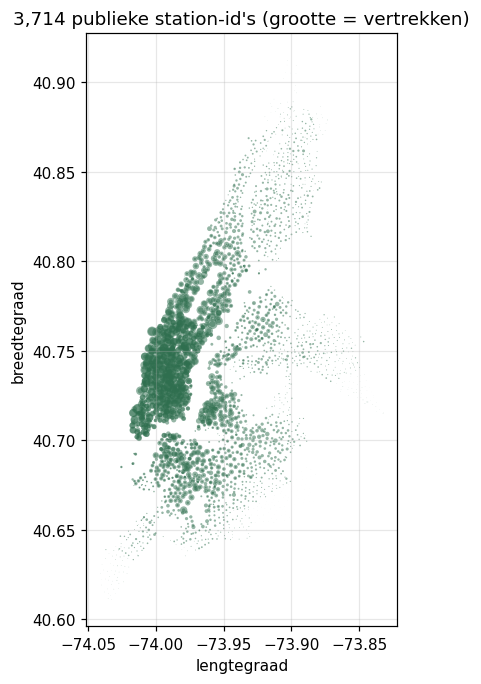

In [17]:
public = st[st["keep"]]
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(public["lng"], public["lat"], s=public["trips"] / public["trips"].max() * 60, c=GREEN, alpha=.5, lw=0)
ax.set(title=f"{len(public):,} publieke station-id's (grootte = vertrekken)", xlabel="lengtegraad", ylabel="breedtegraad")
ax.set_aspect(1 / np.cos(np.radians(40.73)))
plt.show()

De kaart toont de vorm van het netwerk: Manhattan (de lange strook), Brooklyn (zuiden), Queens (oosten) en de Bronx (noorden). De grootste bollen zitten in Midtown en Lower Manhattan.

## 8. Categorische kolommen
**Vaststelling:** alles staat als tekst in de CSV's. Datums en coördinaten zetten we om in `parse_chunk` (§2). `rideable_type` en `member_casual` zijn categorieën met weinig waarden.

In [18]:
raw_sample = pd.read_parquet(DATA_DIR / "trips_sample.parquet")
types = pd.DataFrame({"ruw (CSV)": raw_sample[RAW_COLUMNS].dtypes.astype(str),
                      "na omzetting": parse_chunk(raw_sample[raw_sample["source_file"].str.startswith("2024")][RAW_COLUMNS])
                                      .astype({"rideable_type": "category", "member_casual": "category"})[RAW_COLUMNS].dtypes.astype(str)})
display(types.T)
share = sample.groupby("jaar").agg(member=("member_casual", lambda s: (s == "member").mean() * 100),
                                   ebike=("rideable_type", lambda s: (s == "electric_bike").mean() * 100))
share.round(1).T.rename(index={"member": "% member", "ebike": "% e-bike"})

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
ruw (CSV),object,object,object,object,object,object,object,object,object,object,object,object,object
na omzetting,object,category,datetime64[ns],datetime64[ns],object,object,object,object,float64,float64,float64,float64,category


jaar,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% member,84.6,90.3,87.1,88.5,89.1,89.0,86.5,77.0,73.1,78.1,81.4,80.7,82.3,82.0
% e-bike,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,31.9,39.1,50.2,66.0,70.5,72.4


**Keuze:** `rideable_type` en `member_casual` worden het type `category` (minder geheugen, en duidelijk dat het geen vrije tekst is). We gebruiken ze **niet als kenmerk** voor het model: bij een voorspelling van de vraag weet je niet wie er zal fietsen of met welke fiets. Wel tellen we per zone-uur hoeveel vertrekken van members en met e-bikes waren, om het gedrag te begrijpen (in `02`): het aandeel e-bikes steeg van 0% (vóór 2020) naar ± 70%, het aandeel members zakte tijdens corona.

## 9. Het weer
**Vaststelling:** het weer staat niet in de ritdata, terwijl het (zie de hypotheses in `02`) de grootste factor buiten de kalender is.

**Keuze:** per uur temperatuur, neerslag, wind, sneeuwval, luchtvochtigheid en **sneeuwhoogte** ophalen bij Open-Meteo (gratis archief van weermodellen, geen sleutel nodig), voor één punt in het midden van NYC, in **lokale tijd** zoals de ritdata. Per jaar opgevraagd, zodat elk antwoord klein blijft.
- **Zomertijd:** in maart ontbreekt één uur en in november komt één uur twee keer voor. We ontdubbelen en vullen dat ene uur met interpolatie.
- **Sneeuwhoogte** (cm sneeuw op de grond) kwam er later bij: de foutenanalyse in `02` toonde dat het model de vraag overschatte op droge dagen ná een sneeuwstorm, als er nog sneeuw lag.

In [19]:
WEATHER_VARIABLES = {"temperature_2m": "temperature_c", "precipitation": "precipitation_mm",
                     "wind_speed_10m": "wind_kmh", "snowfall": "snowfall_cm",
                     "relative_humidity_2m": "humidity_pct", "snow_depth": "snow_depth_cm"}


def _get_with_retries(url: str, params: dict, attempts: int = 6) -> dict:
    """GET met herhaalpogingen: de gratis API weigert soms tijdelijk na veel aanvragen."""
    for attempt in range(attempts):
        try:
            response = requests.get(url, params=params, timeout=60)
            response.raise_for_status()
            return response.json()
        except (requests.ConnectionError, requests.HTTPError, requests.Timeout):
            if attempt == attempts - 1:
                raise
            time.sleep(20 * (attempt + 1))


def download_weather(start: str, end: str, path: Path) -> pd.DataFrame:
    """Uurlijks weer voor NYC in lokale tijd (zoals de ritdata), gecachet in `path`."""
    if path.exists():
        return pd.read_parquet(path)
    hourly = _get_with_retries("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": NYC_CENTER[0], "longitude": NYC_CENTER[1], "start_date": start, "end_date": end,
        "hourly": ",".join(WEATHER_VARIABLES), "timezone": "America/New_York", "wind_speed_unit": "kmh"})["hourly"]
    weather = pd.DataFrame(hourly).rename(columns=WEATHER_VARIABLES)
    weather["snow_depth_cm"] = weather["snow_depth_cm"] * 100          # de API geeft meter
    weather["time"] = pd.to_datetime(weather["time"])
    # Zomertijd: het "verdwenen" uur in maart ontbreekt, het dubbele uur in november komt twee keer voor.
    weather = weather.drop_duplicates("time").set_index("time")
    full = pd.date_range(f"{start} 00:00", f"{end} 23:00", freq="h")
    weather = weather.reindex(full).interpolate(limit=2).rename_axis("time").reset_index()
    path.parent.mkdir(parents=True, exist_ok=True)
    weather.to_parquet(path, index=False)
    return weather


def download_weather_range(start: str, end: str, path: Path = DATA_DIR / "weather.parquet") -> pd.DataFrame:
    """Weer over meerdere jaren: per jaar opgevraagd, samengevoegd en gecachet."""
    if path.exists():
        return pd.read_parquet(path)
    years = []
    for year in range(pd.Timestamp(start).year, pd.Timestamp(end).year + 1):
        first = max(pd.Timestamp(start), pd.Timestamp(f"{year}-01-01")).strftime("%Y-%m-%d")
        last = min(pd.Timestamp(end), pd.Timestamp(f"{year}-12-31")).strftime("%Y-%m-%d")
        years.append(download_weather(first, last, path.parent / f"_weather_{year}.parquet"))
        time.sleep(1)                               # vriendelijk voor de gratis API
    weather = pd.concat(years, ignore_index=True).drop_duplicates("time")
    weather.to_parquet(path, index=False)
    for year in range(pd.Timestamp(start).year, pd.Timestamp(end).year + 1):
        (path.parent / f"_weather_{year}.parquet").unlink(missing_ok=True)
    return weather


first = pd.Timestamp(audit.index.min() + "01").strftime("%Y-%m-%d")
last = (pd.Timestamp(audit.index.max() + "01") + pd.offsets.MonthEnd(0)).strftime("%Y-%m-%d")
weather = download_weather_range(first, last)
w = weather.set_index("time")
print(f"{w.index.min()} – {w.index.max()}: {len(w):,} uren, ontbrekende waarden: {int(w.isna().sum().sum())}, "
      f"dubbele uren: {int(w.index.duplicated().sum())}")
w.resample("YS").agg({"temperature_c": "mean", "precipitation_mm": "sum", "snowfall_cm": "sum",
                      "snow_depth_cm": "max"}).round(1).rename(index=lambda t: t.year).T

2013-06-01 00:00:00 – 2026-09-30 23:00:00: 116,880 uren, ontbrekende waarden: 0, dubbele uren: 0


time,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
temperature_c,15.9,11.0,12.0,12.8,12.4,12.2,12.2,13.0,12.8,12.6,13.0,13.1,12.5,14.0
precipitation_mm,686.2,992.4,980.1,898.5,1102.4,1670.4,1328.9,1221.3,1367.5,1352.2,1479.7,1296.8,1104.4,1100.4
snowfall_cm,19.5,99.9,88.3,62.0,78.3,118.4,62.0,31.9,63.5,46.0,22.4,40.2,50.5,62.4
snow_depth_cm,11.0,47.0,45.0,29.0,25.0,16.0,17.0,18.0,30.0,15.0,7.0,14.0,10.0,51.0


Het weer is volledig: elk uur van juni 2013 tot september 2026, zonder ontbrekende waarden. De jaartabel toont ook de verschillen tussen de winters: veel sneeuw in 2014, 2015, 2016 en 2018, weinig in 2020 en 2023, en opnieuw veel in de winter 2025–2026 (de testperiode van het model).

## 10. Dagen waarop het systeem dicht was, en ontbrekende data
**Vaststelling:** we tellen alle vertrekken per dag (publieke stations) en vergelijken elke dag met de mediaan van de 4 weken eromheen. Een dag met heel weinig vertrekken kan echt zijn (sneeuwstorm, Kerstmis) of een **gat in de data** (een bestand dat ontbreekt of afgekapt is).

In [20]:
public_ids = set(st.loc[st["keep"], "start_station_id"])
daily = []
for path in sorted((DATA_DIR / "station_hour").glob("*.parquet")):
    sh = pd.read_parquet(path, columns=["start_station_id", "time", "trips"])
    sh = sh[sh["start_station_id"].isin(public_ids)]
    daily.append(sh.groupby(sh["time"].dt.normalize())["trips"].sum())
daily = pd.concat(daily).groupby(level=0).sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"), fill_value=0)
ratio = daily / daily.rolling(29, center=True, min_periods=10).median()
day_weather = weather.set_index("time").resample("D").agg({"precipitation_mm": "sum", "snowfall_cm": "sum", "snow_depth_cm": "max"})
low = pd.DataFrame({"vertrekken": daily, "verhouding": ratio.round(3)}).join(day_weather.round(1))
print("Dagen onder 3% van de normale vraag:")
low[low["verhouding"] < 0.03]

Dagen onder 3% van de normale vraag:


,vertrekken,verhouding,precipitation_mm,snowfall_cm,snow_depth_cm
2016-01-23,0,0.000,43.9,30.7,29.0
2016-01-24,0,0.000,1.1,0.8,29.0
2016-01-25,0,0.000,0.0,0.0,29.0
2016-01-26,0,0.000,0.0,0.0,29.0
2017-02-09,0,0.000,26.1,18.2,15.0
2017-03-14,0,0.000,46.3,29.0,25.0
2017-03-15,0,0.000,0.6,0.4,25.0
2017-03-16,0,0.000,0.0,0.0,25.0
2020-12-17,180,0.005,21.3,13.9,18.0
2021-02-01,241,0.009,38.4,26.9,25.0


In [21]:
print("Rustige, maar niet gesloten dagen (3–25% van normaal), een greep:")
low[(low["verhouding"] >= 0.03) & (low["verhouding"] < 0.25)].sample(8, random_state=SEED).sort_index()

Rustige, maar niet gesloten dagen (3–25% van normaal), een greep:


,vertrekken,verhouding,precipitation_mm,snowfall_cm,snow_depth_cm
2014-01-22,2451,0.245,0.5,0.7,7.0
2015-02-02,1459,0.191,26.9,8.3,26.0
2018-03-02,6854,0.241,49.8,13.2,8.0
2018-03-21,3755,0.108,24.6,17.2,11.0
2022-05-07,20557,0.228,27.3,0.0,0.0
2023-04-30,24850,0.234,26.0,0.0,0.0
2026-01-25,3051,0.069,33.8,19.0,29.0
2026-02-24,13119,0.226,0.0,0.0,51.0


**Keuze:** de 12 dagen met minder dan 3% van de normale vraag weglaten (`EXCLUDE_DAYS`); alle andere dagen behouden.

**Waarom:** het zijn allemaal dagen met een zware sneeuwstorm (tot 31 cm verse sneeuw, tot 49 cm op de grond) waarop Citi Bike het systeem stillegde, bv. 23–26 januari 2016, 14–16 maart 2017, 1–2 februari 2021 en 23 februari 2026. Er was **geen aanbod**, dus "0 vertrekken" zegt niets over de vraag; het model zou er leren dat sneeuw tot nul ritten leidt, terwijl het om een beslissing van de uitbater ging. De rustige dagen erboven (zware regen, sneeuw, Kerstmis) zijn wél echte vraag: precies wat het model moet leren.

**Zijn er gaten door ontbrekende bestanden?** Per maand: op hoeveel dagen waren er ritten, en hoe verhoudt de maand zich tot dezelfde maand een jaar eerder?

In [22]:
EXCLUDE_DAYS = ["2016-01-23", "2016-01-24", "2016-01-25", "2016-01-26", "2017-02-09", "2017-03-14",
                "2017-03-15", "2017-03-16", "2020-12-17", "2021-02-01", "2021-02-02", "2026-02-23"]
assert sorted(low.index[low["verhouding"] < 0.03].strftime("%Y-%m-%d")) == EXCLUDE_DAYS

monthly = daily.resample("MS").sum()
by_month = pd.DataFrame({"vertrekken": monthly, "dagen_met_data": (daily > 0).resample("MS").sum(),
                         "dagen": monthly.index.days_in_month})
by_month["% van vorig jaar"] = (by_month["vertrekken"] / by_month["vertrekken"].shift(12) * 100).round()
print("Maanden met minstens één dag zonder ritten:")
display(by_month[by_month["dagen_met_data"] < by_month["dagen"]])
print("De testperiode van het model (en de maanden ervoor):")
by_month.loc[by_month.index >= "2025-01-01"]

Maanden met minstens één dag zonder ritten:


,vertrekken,dagen_met_data,dagen,% van vorig jaar
2016-01-01,509478,27,31,178.0
2017-02-01,791526,27,28,141.0
2017-03-01,727515,28,31,79.0
2021-02-01,636758,27,28,55.0
2026-02-01,1218540,27,28,60.0


De testperiode van het model (en de maanden ervoor):


,vertrekken,dagen_met_data,dagen,% van vorig jaar
2025-01-01,2123800,31,31,113.0
2025-02-01,2030549,28,28,96.0
2025-03-01,3166621,31,31,119.0
2025-04-01,3723059,30,30,116.0
2025-05-01,4323432,31,31,105.0
2025-06-01,4756486,30,30,99.0
2025-07-01,4983818,31,31,106.0
2025-08-01,5119526,31,31,111.0
2025-09-01,5284678,30,30,106.0
2025-10-01,4728867,31,31,92.0


**Resultaat:** elke maand is aanwezig, en de enige dagen zonder ritten zijn de gesloten dagen hierboven. De recentste maanden, de testperiode van het model, zijn volledig. Februari 2026 ligt 40% onder februari 2025: een dag gesloten systeem (23/2) en een koude, sneeuwrijke maand met tot 51 cm sneeuw op de grond (§9). Dat is echte (lage) vraag, geen gat. Hetzelfde geldt voor februari 2021 (−45%): twee gesloten dagen, een sneeuwrijke maand en de coronawinter.

## 11. Van stations naar zones
**Vaststelling:** vandaag zijn er ± 2.400 stations. Per station per uur voorspellen zou over 13 jaar ± 100 miljoen rijen geven, waarvan het grootste deel 0 of 1 vertrek: vooral toeval. Voor herverdeling plant Citi Bike bovendien per buurt, niet per station.

**Keuze:** stations groeperen tot **30 zones** met **KMeans** op hun coördinaten (unsupervised learning). KMeans kiest *k* centra, wijst elk station toe aan het dichtstbijzijnde centrum, verplaatst elk centrum naar het gemiddelde van zijn stations, en herhaalt dat tot er niets meer verandert.
- coördinaten eerst omgerekend naar km (`to_km`), zodat noord-zuid en oost-west even zwaar wegen;
- **gewogen met het aantal ritten** (`sample_weight`): KMeans legt de centra dan dichter bij elkaar waar veel gefietst wordt. Drukke buurten (Midtown) krijgen kleinere zones, rustige buurten (Bronx) grotere;
- gefit op het netwerk van de **laatste 12 maanden**: het model voorspelt de toekomst, dus de zones moeten de stad van vandaag beschrijven. Elk station uit elk jaar, ook met een oude id, krijgt daarna de zone van zijn locatie;
- zones hernummerd van druk (0) naar rustig (29); de naam van een zone is het drukste station erin.

**Waarom 30?** We vergelijken verschillende aantallen zones op drie maten:
- **inertia**: de totale (gekwadrateerde) afstand van de stations tot hun zonecentrum; lager = compactere zones (elleboogmethode);
- **silhouette** (−1 tot 1): hoe goed een station bij zijn eigen zone past in plaats van bij de buurzone;
- het **aantal vertrekken per zone-uur**: te weinig = vooral toeval.

2,433 stations in de laatste 12 maanden


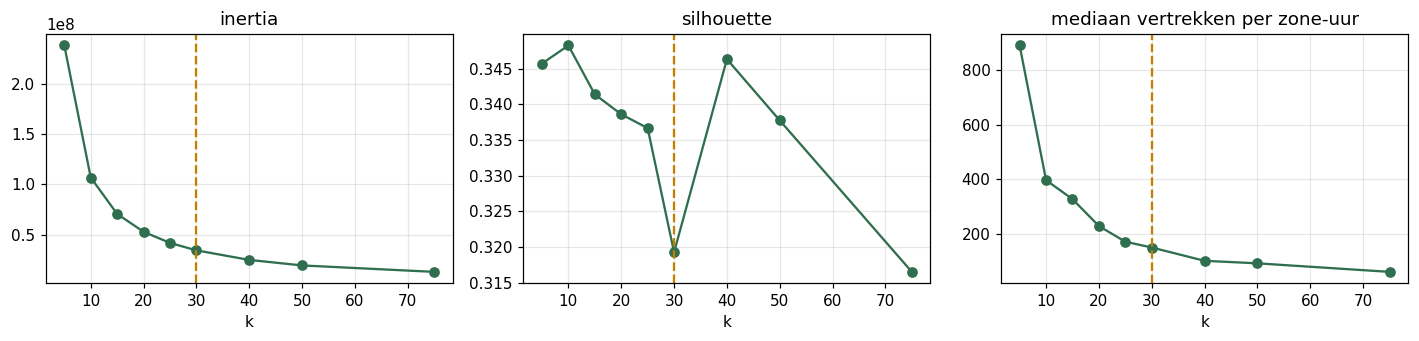

,inertia,silhouette,mediaan vertrekken per zone-uur,rustigste zone
k,,,,
5,2.379030e+08,0.35,891.59,382.98
10,1.068014e+08,0.35,397.04,163.15
15,7.061356e+07,0.34,327.45,78.91
20,5.292079e+07,0.34,228.61,34.89
25,4.184793e+07,0.34,171.10,31.62
30,3.446515e+07,0.32,149.80,31.62
40,2.497541e+07,0.35,100.90,18.86
50,1.949230e+07,0.34,91.70,11.24
75,1.309385e+07,0.32,60.33,10.87


In [23]:
KM_PER_DEG_LAT = 111.0
KM_PER_DEG_LNG = 111.0 * np.cos(np.radians(40.73))   # op de breedtegraad van NYC


def to_km(lat, lng) -> np.ndarray:
    """Graden -> (ongeveer) kilometers, zodat afstanden in beide richtingen even zwaar wegen."""
    return np.column_stack([np.asarray(lat) * KM_PER_DEG_LAT, np.asarray(lng) * KM_PER_DEG_LNG])


def fit_zones(stations: pd.DataFrame, k: int, seed: int = SEED) -> KMeans:
    """KMeans op stationscoördinaten, gewogen met het aantal ritten: drukke buurten krijgen kleinere zones."""
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit(to_km(stations["lat"], stations["lng"]),
                                                                    sample_weight=stations["trips"])


def zone_table(stations: pd.DataFrame, kmeans: KMeans) -> pd.DataFrame:
    """Per zone: id (0 = drukste), naam (drukste station), centrum, aantal stations en ritten."""
    st_ = stations.assign(raw_zone=kmeans.predict(to_km(stations["lat"], stations["lng"])))
    zones = (st_.sort_values("trips", ascending=False).groupby("raw_zone")
                .agg(name=("name", "first"), n_stations=("start_station_id", "size"), trips=("trips", "sum"),
                     lat=("lat", "mean"), lng=("lng", "mean"))
                .sort_values("trips", ascending=False).reset_index())
    zones["zone"] = np.arange(len(zones))
    zones["name"] = "rond " + zones["name"].astype(str)
    return zones[["zone", "raw_zone", "name", "n_stations", "trips", "lat", "lng"]]


def assign_zones(stations: pd.DataFrame, kmeans: KMeans, zones: pd.DataFrame) -> pd.Series:
    """Zone-id (na hernummering) per station, op basis van zijn locatie."""
    mapping = dict(zip(zones["raw_zone"], zones["zone"]))
    return pd.Series(kmeans.predict(to_km(stations["lat"], stations["lng"])), index=stations.index).map(mapping)


def recent_station_trips(station_dir: Path, since: pd.Timestamp) -> pd.Series:
    """Vertrekken per station sinds `since` (om de zones op het netwerk van vandaag te leggen)."""
    parts = []
    for path in sorted(station_dir.glob("*.parquet")):
        sh = pd.read_parquet(path, columns=["start_station_id", "time", "trips"])
        sh = sh[sh["time"] >= since]
        if len(sh):
            parts.append(sh.groupby("start_station_id")["trips"].sum())
    return pd.concat(parts).groupby(level=0).sum()


since = (st.loc[st["keep"], "last_time"].max() + pd.Timedelta(hours=1)) - pd.DateOffset(months=12)
recent_trips = recent_station_trips(DATA_DIR / "station_hour", since)
current = st[st["keep"] & st["start_station_id"].isin(recent_trips.index)].assign(
    trips=lambda d: d["start_station_id"].map(recent_trips).astype(int))
X_km = to_km(current["lat"], current["lng"])
rows = []
for k in [5, 10, 15, 20, 25, 30, 40, 50, 75]:
    km = fit_zones(current, k)
    labels = km.predict(X_km)
    per_zone = current.groupby(labels)["trips"].sum() / (365 * 24)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_km, labels, sample_size=2000, random_state=SEED),
                 "mediaan vertrekken per zone-uur": per_zone.median(), "rustigste zone": per_zone.min()})
choice = pd.DataFrame(rows).set_index("k")
print(f"{len(current):,} stations in de laatste 12 maanden")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["inertia", "silhouette", "mediaan vertrekken per zone-uur"]):
    ax.plot(choice.index, choice[col], "o-", color=GREEN)
    ax.axvline(N_ZONES, color=ORANGE, ls="--")
    ax.set(title=col, xlabel="k")
plt.tight_layout()
plt.show()
choice.round(2)

**Interpretatie en keuze: 30 zones.**
- De **inertia** daalt steil tot ± 20 à 30 zones en daarna nog maar langzaam (elleboog): meer zones maken de groepen nauwelijks compacter.
- De **silhouette** is voor elke k ongeveer gelijk (0,32–0,35): de stations vormen geen natuurlijk gescheiden groepen, de stad is één doorlopend netwerk. Ze helpt dus niet om k te kiezen; de keuze is een **praktische afweging**.
- De doorslag geeft het **aantal vertrekken per zone-uur**: met 30 zones heeft de mediane zone ± 150 vertrekken per uur en zelfs de rustigste nog ± 32. Bij 40 zones zakt de rustigste naar 19, bij 75 naar 11: dan domineert het toeval.

Een zone telt zo gemiddeld ± 80 stations: een buurt van een paar km², de schaal waarop fietsen herverdeeld worden.

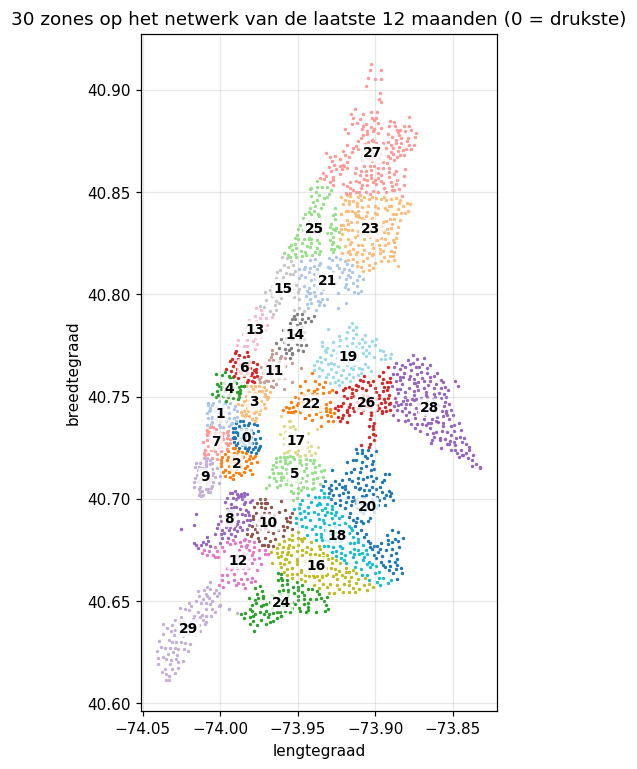

,zone,name,n_stations,trips
0,0,rond Broadway & E 14 St,55,3171045
1,1,rond W 21 St & 6 Ave,48,3117937
2,2,rond Norfolk St & Broome St,52,2691235
3,3,rond Park Ave & E 42 St,47,2687753
4,4,rond W 31 St & 7 Ave,43,2686707
5,5,rond Metropolitan Ave & Bedford Ave,77,2497805
6,6,rond Broadway & W 58 St,42,2404518
7,7,rond Carmine St & 6 Ave,46,2379871
8,8,rond Schermerhorn St & Hoyt St,79,2069796
9,9,rond West St & Liberty St,56,1855619


In [24]:
kmeans = fit_zones(current, N_ZONES)
zones_now = zone_table(current, kmeans)
current = current.assign(zone=assign_zones(current, kmeans, zones_now).to_numpy())
fig, ax = plt.subplots(figsize=(7, 8))
cmap = plt.get_cmap("tab20")
for z in zones_now["zone"]:
    part = current[current["zone"] == z]
    ax.scatter(part["lng"], part["lat"], s=5, color=cmap(z % 20), lw=0)
for _, z in zones_now.iterrows():
    ax.text(z["lng"], z["lat"], str(z["zone"]), fontsize=9, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.8))
ax.set(title="30 zones op het netwerk van de laatste 12 maanden (0 = drukste)", xlabel="lengtegraad", ylabel="breedtegraad")
ax.set_aspect(1 / np.cos(np.radians(40.73)))
plt.show()
zones_now[["zone", "name", "n_stations", "trips"]].head(10)

Door de weging met het aantal ritten zijn de zones in Lower Manhattan, Midtown en Williamsburg (de lage nummers) klein en heel druk, terwijl de zones in de Bronx, Queens en het zuiden van Brooklyn (de hoge nummers) veel groter zijn, met 100 tot 200 stations. Een zone is zo telkens "een gebied met genoeg ritten om te plannen".

## 12. Het netwerk groeit: aanbod als kenmerk
**Vaststelling:** het aantal stations met minstens één vertrek groeide sterk, en niet overal tegelijk.

Gemiddeld aantal actieve stations (unieke locaties) per maand:


m,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
actieve stations,330.0,329.0,380.0,525.0,652.0,762.0,805.0,1002.0,1423.0,1581.0,1896.0,2130.0,2154.0,2265.0


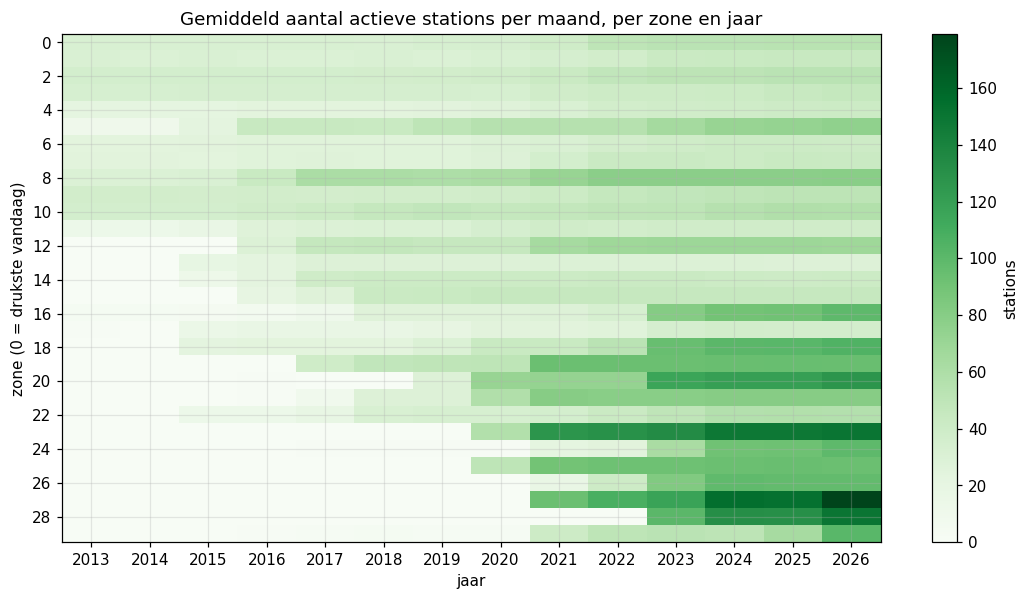

In [25]:
station_zone_all = pd.Series(assign_zones(public, kmeans, zones_now).to_numpy(), index=public["start_station_id"])
act = ids_per_month[ids_per_month["start_station_id"].isin(public_ids)].assign(
    loc=lambda d: d["start_station_id"].map(location), zone=lambda d: d["start_station_id"].map(station_zone_all))
active = act.groupby("m")["loc"].nunique()
print("Gemiddeld aantal actieve stations (unieke locaties) per maand:")
display(active.groupby(active.index.year).mean().round().to_frame("actieve stations").T)
zone_years = (act[["zone", "m", "loc"]].drop_duplicates().groupby(["zone", "m"]).size().rename("actief").reset_index()
              .assign(jaar=lambda d: d["m"].dt.year).groupby(["zone", "jaar"])["actief"].mean().unstack(fill_value=0).round())
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(zone_years.values, aspect="auto", cmap="Greens")
ax.set(xticks=range(zone_years.shape[1]), xticklabels=zone_years.columns, yticks=range(0, N_ZONES, 2),
       xlabel="jaar", ylabel="zone (0 = drukste vandaag)", title="Gemiddeld aantal actieve stations per maand, per zone en jaar")
plt.colorbar(im, ax=ax, label="stations")
plt.show()

De zones met de laagste nummers (Midtown, Lower Manhattan, Williamsburg) bestaan al sinds 2013. De hoge nummers (de Bronx, Queens, East Harlem, Bushwick, Flatbush, Sunset Park) krijgen pas tussen 2019 en 2023 stations, en sommige groeien nog in 2026.

**Keuze:**
- per zone en per maand het aantal **actieve stations** (unieke locaties met minstens één vertrek) toevoegen als **kenmerk**;
- **zone-uren zonder enig actief station weglaten**.

**Waarom:** een zone-uur zonder station is geen "0 vraag" maar "geen aanbod" (in 2014 was er in de Bronx niets te meten). En een zone met 20 stations vraagt minder fietsen dan dezelfde zone met 150 stations: zonder dat kenmerk kan het model de groei niet volgen. Bij een voorspelling voor de toekomst gebruikt de API het **huidige** aantal actieve stations per zone. We tellen **locaties**, geen id's: anders zou de overstap op nieuwe id's (§6) in 2019 lijken op een plotse uitbreiding.

## 13–14. Rooster, weer en split
**13. Volledig rooster.** `station_hour` bevat alleen uren met minstens één vertrek. Voor het model moeten ook de uren **zonder** vertrek erin staan (als 0), anders leert het alleen van uren met vraag en overschat het altijd. We bouwen daarom elke combinatie zone × uur en vullen de gaten met 0. Daarna komen het weer (§9) en het aantal actieve stations (§12) erbij, en vallen de zone-uren zonder aanbod en de gesloten dagen (§10) weg.

**14. Split.** De **testset** is de laatste 12 maanden (oktober 2025 – september 2026): zo meten we zoals het model gebruikt wordt (getraind op het verleden, voorspellend voor de toekomst), en zit elk seizoen er één keer in. Voor het kiezen en tunen gebruiken we binnen de trainset **backtesting** (3 folds: trainen op alle jaren vóór een validatiejaar, valideren op dat jaar), zie `02`.

In [26]:
def split_last_months(time_: pd.Series, months: int = 12) -> pd.Series:
    """'test' voor de laatste `months` maanden van de data, anders 'train'."""
    time_ = pd.to_datetime(time_)
    cutoff = (time_.max() + pd.Timedelta(hours=1)) - pd.DateOffset(months=months)
    return pd.Series(np.where(time_ >= cutoff, "test", "train"), index=time_.index)


def prepare_full_table(station_dir: Path, stations: pd.DataFrame, weather: pd.DataFrame,
                       n_zones: int = N_ZONES, recent_months: int = 12, exclude_days=()):
    """Rooster zone x uur over alle jaren. Geeft (table, zones, publieke stations met zone) terug.

    1. stations opschonen (§7); 2. zones op het netwerk van de laatste 12 maanden (§11);
    3. elk station uit elk jaar krijgt de zone van zijn locatie; 4. per zone en uur de vertrekken, per zone en maand
    de actieve stations (unieke locaties, §12); 5. zone-uren zonder aanbod en `exclude_days` (§10) vallen weg;
    6. weer erbij (§9) en split (§14).
    """
    st_ = clean_stations(stations)
    public_ = st_[st_["keep"]].reset_index(drop=True)
    since_ = (public_["last_time"].max() + pd.Timedelta(hours=1)) - pd.DateOffset(months=recent_months)
    recent_ = recent_station_trips(station_dir, since_)
    current_ = public_[public_["start_station_id"].isin(recent_.index)].copy()
    current_["trips"] = current_["start_station_id"].map(recent_).astype(int)

    kmeans_ = fit_zones(current_, n_zones)
    zones_ = zone_table(current_, kmeans_)
    public_["zone"] = assign_zones(public_, kmeans_, zones_).astype(int)
    station_zone = public_.set_index("start_station_id")["zone"]
    station_location = station_locations(public_)

    counts, active_ = [], []
    for path in sorted(station_dir.glob("*.parquet")):
        sh = pd.read_parquet(path)
        sh["zone"] = sh["start_station_id"].map(station_zone)
        sh = sh[sh["zone"].notna()]
        sh["zone"] = sh["zone"].astype(int)
        counts.append(sh.groupby(["zone", "time"])[["trips", "members", "electric"]].sum())
        active_.append(sh.assign(month=sh["time"].dt.to_period("M"), location=sh["start_station_id"].map(station_location))
                         [["zone", "month", "location"]].drop_duplicates())
    counts = pd.concat(counts).groupby(level=[0, 1]).sum()
    active_ = pd.concat(active_).drop_duplicates().groupby(["zone", "month"]).size().rename("active_stations")

    hours = pd.date_range(counts.index.get_level_values("time").min().floor("D"),
                          counts.index.get_level_values("time").max().ceil("D") - pd.Timedelta(hours=1), freq="h")
    grid = pd.MultiIndex.from_product([range(n_zones), hours], names=["zone", "time"])
    table_ = counts.reindex(grid, fill_value=0).reset_index()
    table_["month_period"] = table_["time"].dt.to_period("M")
    table_ = table_.merge(active_.reset_index().rename(columns={"month": "month_period"}), on=["zone", "month_period"], how="left")
    table_["active_stations"] = table_["active_stations"].fillna(0).astype(int)
    table_ = table_[table_["active_stations"] > 0].drop(columns="month_period")
    if len(exclude_days):
        table_ = table_[~table_["time"].dt.normalize().isin(pd.to_datetime(list(exclude_days)))]
    table_ = table_.merge(weather, on="time", how="left")
    table_["split"] = split_last_months(table_["time"])

    latest = active_.reset_index()
    latest = latest[latest["month"] == latest["month"].max()].set_index("zone")["active_stations"]
    zones_["active_stations"] = zones_["zone"].map(latest).fillna(0).astype(int)
    return table_.reset_index(drop=True), zones_.drop(columns="raw_zone"), public_


table, zones, public_stations = prepare_full_table(DATA_DIR / "station_hour", stations, weather, exclude_days=EXCLUDE_DAYS)
print(f"Modeltabel: {len(table):,} zone-uren van {table['time'].min()} tot {table['time'].max()}")
print(f"Uren zonder vertrek: {(table['trips'] == 0).mean():.1%}; gemiddeld {table['trips'].mean():.1f} vertrekken per zone-uur")
table.head()

Modeltabel: 2,818,992 zone-uren van 2013-06-01 00:00:00 tot 2026-09-30 23:00:00
Uren zonder vertrek: 4.2%; gemiddeld 116.6 vertrekken per zone-uur


,zone,time,trips,members,electric,active_stations,temperature_c,precipitation_mm,wind_kmh,snowfall_cm,humidity_pct,snow_depth_cm,split
0,0,2013-06-01 00:00:00,24,21,0,32,22.7,0.0,11.2,0.0,65,0.0,train
1,0,2013-06-01 01:00:00,10,9,0,32,21.9,0.0,10.5,0.0,70,0.0,train
2,0,2013-06-01 02:00:00,7,4,0,32,21.2,0.0,10.5,0.0,75,0.0,train
3,0,2013-06-01 03:00:00,8,3,0,32,20.6,0.0,9.7,0.0,78,0.0,train
4,0,2013-06-01 04:00:00,2,2,0,32,20.1,0.0,9.7,0.0,83,0.0,train


## 15. Controles
1. Geen dubbele (zone, uur)-rijen en geen ontbrekende waarden.
2. **Er gaan geen vertrekken verloren**, behalve op de 12 gesloten dagen: de som van `trips` is gelijk aan alle vertrekken van de publieke stations op de overige dagen.
3. Elke rij heeft minstens één actief station.
4. De testset beslaat de laatste 12 maanden.

In [27]:
assert not table.duplicated(["zone", "time"]).any()
assert table.notna().all().all(), table.isna().sum()
assert (table["active_stations"] > 0).all()
kept = set(public_stations["start_station_id"])
excluded = pd.to_datetime(EXCLUDE_DAYS)
expected = 0
for path in sorted((DATA_DIR / "station_hour").glob("*.parquet")):
    sh = pd.read_parquet(path, columns=["start_station_id", "time", "trips"])
    expected += sh.loc[sh["start_station_id"].isin(kept) & ~sh["time"].dt.normalize().isin(excluded), "trips"].sum()
assert table["trips"].sum() == expected, (table["trips"].sum(), expected)
test = table[table["split"] == "test"]
print(f"OK: {len(table):,} rijen, {table['trips'].sum():,} vertrekken "
      f"({table['trips'].sum() / audit['rows'].sum():.2%} van alle ruwe ritten); "
      f"test {test['time'].min():%Y-%m-%d} t/m {test['time'].max():%Y-%m-%d} ({len(test) / len(table):.1%})")

OK: 2,818,992 rijen, 328,688,926 vertrekken (99.97% van alle ruwe ritten); test 2025-10-01 t/m 2026-09-30 (9.3%)


## 16. Is de data verbeterd?
Wat we kregen tegenover wat we nu hebben:

In [28]:
before = {"rijen": f"{int(audit['rows'].sum()):,}", "eenheid": "1 rit",
          "kolomschema's / datumnotaties": f"{scan[['kolommen', 'n_kolommen']].drop_duplicates().shape[0]} / {scan['notatie'].nunique()}",
          "dubbele CSV-versies": n_dropped,
          "ritten zonder startlocatie": f"{int(audit['no_start_station'].sum()):,}",
          "station-id's als getal opgeslagen": f"{int(audit['station_id_fixed'].sum()):,}",
          "vertrekken van interne/JC-HB-stations": f"{int(st.loc[~st['keep'], 'trips'].sum()):,}",
          "gesloten dagen": len(EXCLUDE_DAYS), "uren zonder vertrek in de data": "ontbreken", "weer": "niet aanwezig"}
after = {"rijen": f"{len(table):,}", "eenheid": "1 zone-uur (incl. 0)", "kolomschema's / datumnotaties": "1 / 1",
         "dubbele CSV-versies": 0, "ritten zonder startlocatie": 0, "station-id's als getal opgeslagen": 0,
         "vertrekken van interne/JC-HB-stations": 0, "gesloten dagen": 0,
         "uren zonder vertrek in de data": f"{int((table['trips'] == 0).sum()):,} (als 0)", "weer": "elk uur, 6 variabelen"}
print(f"Vertrekken behouden: {table['trips'].sum():,} van {int(audit['rows'].sum()):,} ruwe rijen "
      f"({table['trips'].sum() / audit['rows'].sum():.2%})")
pd.DataFrame({"ruw": before, "na cleaning": after})

Vertrekken behouden: 328,688,926 van 328,800,493 ruwe rijen (99.97%)


,ruw,na cleaning
rijen,"328,800,493","2,818,992"
eenheid,1 rit,1 zone-uur (incl. 0)
kolomschema's / datumnotaties,3 / 3,1 / 1
dubbele CSV-versies,21,0
ritten zonder startlocatie,"92,077",0
station-id's als getal opgeslagen,"17,320,781",0
vertrekken van interne/JC-HB-stations,"18,813",0
gesloten dagen,12,0
uren zonder vertrek in de data,ontbreken,"117,517 (als 0)"
weer,niet aanwezig,"elk uur, 6 variabelen"


## 17. Dezelfde stappen voor de studie op 2024
In `02` vergelijken we eerst alle technieken op **één jaar** (2024): daar duurt een model trainen seconden in plaats van minuten. Die studie gebruikt dezelfde cleaning, met drie verschillen:
- de zones worden gefit op de stations **van 2024** (gewogen met hun ritten in 2024);
- alleen 2024: geen groei, dus geen `active_stations` en geen `year`. Er waren in 2024 geen gesloten dagen;
- de **testset** is de laatste 7 dagen van elke maand (`split_labels`): zo zit elk seizoen in de test (een split "laatste twee maanden" zou alleen winter testen), en zijn de test-uren blokken van een week (minder lek via naburige uren).

De stationslijst van 2024 maken we uit de stationsdelen van de 12 maandbestanden van 2024 (§4), het weer is dat van §9.

In [29]:
def split_labels(time_: pd.Series) -> pd.Series:
    """'test' voor de laatste 7 dagen van elke maand, anders 'train' (studie op 2024)."""
    time_ = pd.to_datetime(time_)
    return pd.Series(np.where(time_.dt.day > (time_.dt.days_in_month - 7), "test", "train"), index=time_.index)


def build_zone_hour(station_hour: pd.DataFrame, station_zone: pd.Series, n_zones: int,
                    weather: pd.DataFrame, year: int) -> pd.DataFrame:
    """Volledig rooster zone x uur voor één jaar (uren zonder vertrek = 0), met het weer erbij."""
    sh = station_hour.assign(zone=station_hour["start_station_id"].map(station_zone))
    sh = sh[sh["zone"].notna() & (sh["time"].dt.year == year)]
    counts = sh.groupby(["zone", "time"])[["trips", "members", "electric"]].sum()
    hours = pd.date_range(f"{year}-01-01 00:00", f"{year}-12-31 23:00", freq="h")
    grid = pd.MultiIndex.from_product([range(n_zones), hours], names=["zone", "time"])
    counts.index = counts.index.set_levels(counts.index.levels[0].astype(int), level=0)
    return counts.reindex(grid, fill_value=0).reset_index().merge(weather, on="time", how="left")


sh24 = pd.concat(pd.read_parquet(p) for p in sorted((DATA_DIR / "station_hour").glob("2024*.parquet")))
sh24 = sh24.groupby(["start_station_id", "time"], as_index=False)[["trips", "members", "electric"]].sum()
st24 = combine_stations(pd.concat(pd.read_parquet(p) for p in sorted((DATA_DIR / "_stations").glob("2024*.parquet"))))
st24["lat"] = st24.pop("lat_sum") / st24["trips"]
st24["lng"] = st24.pop("lng_sum") / st24["trips"]
st24 = st24[["start_station_id", "name", "lat", "lng", "trips"]]
w24 = weather[weather["time"].dt.year == 2024].drop(columns="snow_depth_cm").reset_index(drop=True)

public24 = clean_stations(st24).query("keep").reset_index(drop=True)
kmeans24 = fit_zones(public24, N_ZONES)
zones24 = zone_table(public24, kmeans24)
public24["zone"] = assign_zones(public24, kmeans24, zones24)
table24 = build_zone_hour(sh24, public24.set_index("start_station_id")["zone"], N_ZONES, w24, 2024)
table24["split"] = split_labels(table24["time"])
table24 = table24.astype({"zone": "int16", "trips": "int32", "members": "int32", "electric": "int32"})
print(f"2024: {len(st24):,} station-id's, waarvan {len(public24):,} publiek; {len(table24):,} zone-uren, "
      f"{table24['trips'].sum():,} vertrekken, {(table24['trips'] == 0).mean():.1%} zonder vertrek; "
      f"test {(table24['split'] == 'test').mean():.1%}")
zones24[["zone", "name", "n_stations", "trips"]].head(10)

2024: 2,280 station-id's, waarvan 2,210 publiek; 263,520 zone-uren, 44,269,890 vertrekken, 0.3% zonder vertrek; test 23.0%


,zone,name,n_stations,trips
0,0,rond W 21 St & 6 Ave,51,3109617
1,1,rond University Pl & E 14 St,53,3071486
2,2,rond E 33 St & 1 Ave,48,2745216
3,3,rond Canal St & Rutgers St,55,2590015
4,4,rond Broadway & W 58 St,44,2543290
5,5,rond 8 Ave & W 31 St,37,2412386
6,6,rond Cleveland Pl & Spring St,43,2326064
7,7,rond West St & Chambers St,53,1961273
8,8,rond W 100 St & Broadway,89,1801415
9,9,rond Hanson Pl & Ashland Pl,64,1782047


## 18. Opslaan
- `model_table.parquet`: de tabel voor het definitieve model (en voor `train.py`). Dit bestand staat in Git, zodat iedereen het model kan hertrainen zonder 32 GB te downloaden.
- `zones.json`: id, naam, centrum, grootte en het **huidige aantal actieve stations** van elke zone (de API gebruikt dat laatste als kenmerk bij voorspellingen voor de toekomst).
- `station_zones.parquet`: welk station (uit welk jaar) in welke zone ligt.
- `2024/`: de modeltabel, zones, stations, station-uren en het weer van de studie op 2024.

In [30]:
columns = ["zone", "time", "trips", "members", "electric", "active_stations", "temperature_c", "precipitation_mm",
           "wind_kmh", "snowfall_cm", "snow_depth_cm", "humidity_pct", "split"]
table = table[columns].astype({"zone": "int16", "trips": "int32", "members": "int32", "electric": "int32",
                               "active_stations": "int16"})
table.to_parquet(DATA_DIR / "model_table.parquet", index=False)
zones_records = zones.assign(lat=zones["lat"].round(5), lng=zones["lng"].round(5)).to_dict("records")
(DATA_DIR / "zones.json").write_text(json.dumps(zones_records, indent=2, default=int), encoding="utf-8")
public_stations.to_parquet(DATA_DIR / "station_zones.parquet", index=False)

DATA_2024.mkdir(parents=True, exist_ok=True)
table24.to_parquet(DATA_2024 / "model_table.parquet", index=False)
zones24_out = zones24.drop(columns="raw_zone")
(DATA_2024 / "zones.json").write_text(json.dumps(zones24_out.assign(lat=zones24_out["lat"].round(5), lng=zones24_out["lng"].round(5))
                                                 .to_dict("records"), indent=2, default=int), encoding="utf-8")
st24.to_parquet(DATA_2024 / "stations.parquet", index=False)
public24.to_parquet(DATA_2024 / "station_zones.parquet", index=False)
sh24.to_parquet(DATA_2024 / "station_hour.parquet", index=False)
w24.to_parquet(DATA_2024 / "weather_2024.parquet", index=False)
for path in [DATA_DIR / "model_table.parquet", DATA_2024 / "model_table.parquet"]:
    print(f"{path.relative_to(KOBE)}: {path.stat().st_size / 1e6:.1f} MB")

data\model_table.parquet: 27.8 MB
data\2024\model_table.parquet: 2.3 MB


## Samenvatting
| | |
|---|---|
| Ruwe data | 44 bestanden, 32,5 GB, 426 CSV's, **328,8 miljoen ritten** (juni 2013 – september 2026) |
| Bruikbaar als vertrek | 99,97% |
| Weggelaten | 21 dubbele CSV-versies, ritten zonder startlocatie (0,03%), 110 interne/JC-stations (0,006%), 12 gesloten dagen |
| Bewust **niet** weggelaten | ritten zonder einde, lange en negatieve ritduren, "dubbele" rijen uit 2013–2017 |
| Herstelde gegevens | drie generaties kolomnamen, drie datumnotaties, station-id's die als getal waren opgeslagen |
| Gecontroleerd | weer volledig, geen ontbrekende maanden, geen vertrekken verloren |
| Modeltabel (alle jaren) | **2.818.992 zone-uren** (30 zones × uren met aanbod), 328,7 miljoen vertrekken, gemiddeld 117 per zone-uur, 4% zonder vertrek |
| Modeltabel (2024) | 263.520 zone-uren (30 zones × 8.784 uren), 44,3 miljoen vertrekken |
| Kenmerken klaar voor het model | zone, kalender, weer (incl. sneeuwhoogte), jaar, actieve stations |
| Test | alle jaren: oktober 2025 – september 2026 (9,3% van de rijen); 2024: laatste 7 dagen van elke maand |

Volgende stap: `02_analyse_en_modellen.ipynb`.